# E105 · The on-sale rush and when to spend: instant sell-outs and the timing of media

| | |
|---|---|
| **Type** | Advanced worked example - read, run, modify |
| **Data** | Real: daily **English Wikipedia pageviews** (Wikimedia, CC0) of the Coldplay, Eras Tour and Oasis articles around three tour on-sales (2021, 2022, 2024), the **shape** of an on-sale rush in attention; E104's **Hotel Booking Demand** data (Antonio, de Almeida & Nunes 2019, *Data in Brief* 22:41-49; CC BY 4.0) over 39 lead weeks for 666 events (25,429 real kept bookings), the late build. Simulated on top: windows of 3-9 months, popularity, the pool of fans, capacity, a queue, spend under several habits, a media effect that changes with lead time, and pull-forward, so that every estimate can be graded |
| **You will learn** | A third clock, **weeks since the on-sale**, and a **finite-pool** model · **instant sell-outs** and an outside measurement of demand · **rescue budgets** and the sign-flipped random-intercept trap · a smooth **response by lead time** $\beta(l)$ in PyMC · why randomising **timing alone** is not enough · plans chosen **over the posterior**, with each decision made on what is known at the time · **re-planning** from the pace · pull-forward |

In [1]:
import os

for v_ in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ[v_] = "1"  # nutpie runs chains as threads: a BLAS pool per chain would fight over the cores

import logging
import sys
import time
import warnings

import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc as pm
import pytensor.tensor as pt
import scipy.sparse as sp
from scipy import stats
from scipy.interpolate import BSpline
from scipy.optimize import minimize
from scipy.special import logsumexp

from pymc_challenges import data

RANDOM_SEED = 105
rng = np.random.default_rng(RANDOM_SEED)
az.style.use("arviz-variat")
logging.getLogger("pymc").setLevel(logging.WARNING)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning, module="arviz")
sys.modules.pop("jax", None)  # arviz leaves a lazy jax stub that makes matplotlib import all of JAX
pd.set_option("display.width", 160)
T_START = time.time()

BLUE, ORANGE, AQUA, PURPLE, RED = "#2a78d6", "#eb6834", "#1baf7a", "#8c5ac8", "#c8384e"
INK, MUTED, LIGHT = "#222222", "#8a8984", "#d9d8d3"
print(f"PyMC {pm.__version__}, ArviZ {az.__version__}")

PyMC 6.3.2, ArviZ 1.3.0


## The setting

E104 asked what a ticketing platform's media spend buys for events with a fixed number of seats,
and found that the habits of spending - stopping at the sell-out, pacing, budgets that follow size
- fool the obvious model. Its events went on sale four months ahead and sold along one smooth
booking curve. Two questions it could not reach come up as soon as the events are concerts.

The first is the **on-sale rush**. A hot show sells out within hours of its release, and the rest
of its window is empty, while the marketing team spends heavily around the announcement and the
release. Is the rush the media's doing, and what can an event that sold out in its first week
teach about demand or media? The second is **when to spend**. A media plan is a schedule: money in
the awareness months, a burst at the on-sale, a final push. Whether a euro works better three
months out or in the last week is a question about how the response changes with lead time, and
it is hard to answer from observational data because every event follows much the same habit.

Concerts add a third clock to E104's two. Lead time $l$ is the weeks until the event and the
booking date $d$ is the calendar; **weeks since the on-sale** is $k = d - S_e$, where the on-sale
date $S_e$ differs from event to event: a tour may go on sale three months or nine months before
the show. With a sales window of $n_e$ weeks and both clocks counted from 0 (lead week 0 is the
event's week, on-sale week 0 the release week), $k = n_e - 1 - l$. The natural model is

$$\log \mu_{el} = a_e + f(l) + h(k) + g(d) + \beta A_{el},$$

and it is identified only because windows differ: if every event went on sale 26 weeks ahead, $k$
and $l$ would be one clock (and, as in E104, a linear trend in any clock can be rewritten as
trends in the others).

The questions are old ones. Nerlove & Arrow (1962) posed the timing of advertising as a control
problem with a stock of goodwill that spend builds and time erodes; adstock is that stock. Whether
to spend evenly or in bursts depends on the curvature of the response: Mahajan & Muller (1986)
showed that pulsing beats an even schedule when the response is convex at low spend and loses when
it is concave. Ticket markets have their own literature on underpricing and resale (Courty 2003):
events are priced below what the market would bear, so demand above capacity exists and sales
cannot show it once an event is full. Re-planning a schedule as sales come in is close to a bandit
problem, for which Thompson sampling, acting on a posterior draw, is the reference rule (Russo,
Van Roy, Kazerouni, Osband & Wen 2018).

No public ticketing data come with on-sale dates, let alone spend, so the data are partly real:
**Wikipedia pageviews** around three tour announcements give the shape of the rush, and E104's
**hotel bookings**, over 39 weeks of lead time, the real late build. The rest is simulated, so that
every estimate can be graded.

| part | question | tool |
|---|---|---|
| A | What does an on-sale look like? | real attention around three tours, the rush kernel; the real late build over 39 weeks |
| B | How do we build the world? | windows of 3-9 months, a pool released at the on-sale, the tilted late build, capacity, a queue, spending habits |
| C | What does the lead-time model make of the rush? | fast Poisson panels: lead time only, three clocks, the pool model; equal windows; flat spend |
| D | What do instant sell-outs teach? | censoring, dropping them, their demand with and without the queue |
| E | Who gets the money? | rescue budgets, the sign flip and Mundlak; pre-sale spend that follows popularity |
| F | When does a euro work? | a PyMC pool model with a smooth $\beta(l)$, the queue as a measurement, two dispersions; observational data against two experiments; predictive checks |
| G | What should the plan be? | pre-sale money at the announcement, in-window plans at the release, over posterior draws against the plug-in; re-planning from the pace; pull-forward |
| H | Films and games | a wishlist as measurement and mediator; pointers to E106 and E104 |

## A · What an on-sale looks like

### A1 · Real attention around three tours

The pageview file holds daily views of three English Wikipedia articles by people (not bots)
around three announcements whose dates are public: Coldplay's Music of the Spheres tour (announced
14 October 2021, general sale on 22 October), The Eras Tour (its article starts on the
announcement day, 1 November 2022; the first presale opened on 15 November) and the Oasis reunion
(announced 27 August 2024, on sale 31 August). For each we take the **excess** attention over a
baseline, the median of days 42-70 after the on-sale, sum it by week for the six weeks from the
on-sale, and normalise. The mean of the three weekly shapes is the **rush kernel** $K_k$ that the
simulated rush will follow.

In [2]:
data.describe("e105_tour_pageviews")
pv = data.load("e105_tour_pageviews")
pv["date"] = pd.to_datetime(pv.date)
TOURS = list(pv.tour.unique())
ker_rows, KER_T = [], []
for tour, g in pv.groupby("tour", sort=False):
    ann, onsale = pd.Timestamp(g.announced.iloc[0]), pd.Timestamp(g.on_sale.iloc[0])
    s = g.set_index("date").views
    base = s[onsale + pd.Timedelta(days=42): onsale + pd.Timedelta(days=70)].median()   # attention after the rush
    ex = (s[onsale: onsale + pd.Timedelta(days=41)] - base).clip(lower=0).to_numpy()   # six weeks from the on-sale
    wk = ex.reshape(6, 7).sum(1)
    KER_T.append(wk / wk.sum())
    pre = (s[ann: onsale - pd.Timedelta(days=1)] - base).clip(lower=0).sum()
    before = s[ann - pd.Timedelta(days=21): ann - pd.Timedelta(days=1)]          # empty for an article that starts at ann
    ker_rows.append({"tour": tour.split(":")[0], "announced": f"{ann:%d %b %Y}", "on sale": f"{onsale:%d %b %Y}",
                     "median, 3 weeks before": f"{before.median():.0f}" if len(before) else "-",
                     "peak views": int(s[ann - pd.Timedelta(days=3): onsale + pd.Timedelta(days=41)].max()),
                     "sale-day views": int(s[onsale]),
                     "baseline after": int(base), "week 0 share": KER_T[-1][0],
                     "first 3 days of week 0": ex[:3].sum() / ex[:7].sum(),
                     "pre-sale / on-sale week": pre / ex[:7].sum()})
KER = np.mean(KER_T, 0)                       # weekly shares of the rush, weeks 0-5 after the on-sale
NK = len(KER)
print(pd.DataFrame(ker_rows).round(2).to_string(index=False))
print("rush kernel, mean of the three tours, weeks 0-5 after the on-sale: " + ", ".join(f"{v:.3f}" for v in KER))

e105_tour_pageviews: One row per tour and day: tour, article, date, views (daily user pageviews), announced, on_sale (public dates, the same on every row of a tour). Attention, not ticket sales.
  source: Wikimedia Foundation pageview statistics (REST API, per-article daily views by users, all access methods), released CC0. Three English Wikipedia articles around three concert-tour announcements: 'Coldplay' (Music of the Spheres World Tour, announced 2021-10-14, general sale 2021-10-22), 'The_Eras_Tour' (announced 2022-11-01, first presale 2022-11-15; the article starts on the announcement day) and 'Oasis_(band)' (Live '25, announced 2024-08-27, on sale 2024-08-31). The url is the first of the three requests. DERIVED by tools/build_e105_data.py - keep the cached file.
  url:    https://wikimedia.org/api/rest_v1/metrics/pageviews/per-article/en.wikipedia/all-access/user/Coldplay/daily/20210815/20220313
        tour   announced     on sale median, 3 weeks before  peak views  sale-day vie

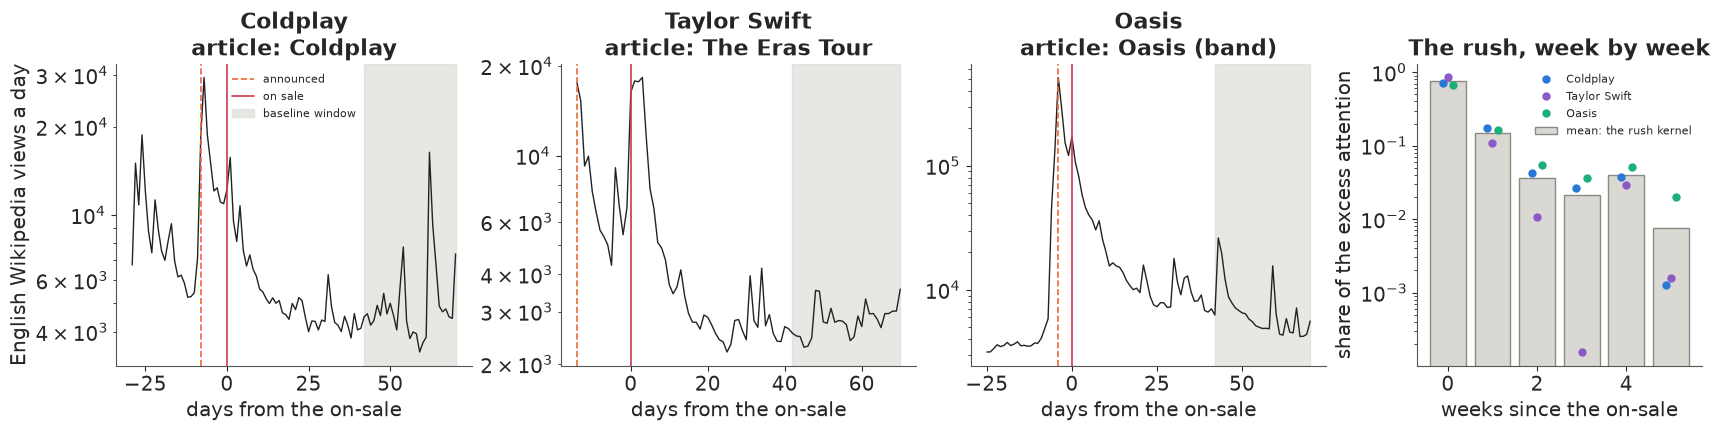

In [3]:
fig, axes = plt.subplots(1, 4, figsize=(17, 4.2), gridspec_kw=dict(width_ratios=[1, 1, 1, 0.8]))
for ax, (tour, g) in zip(axes, pv.groupby("tour", sort=False)):
    ann, onsale = pd.Timestamp(g.announced.iloc[0]), pd.Timestamp(g.on_sale.iloc[0])
    w = g[(g.date >= ann - pd.Timedelta(days=21)) & (g.date <= onsale + pd.Timedelta(days=70))]
    ax.plot((w.date - onsale).dt.days, w.views, color=INK, lw=1)
    ax.axvline((ann - onsale).days, color=ORANGE, lw=1.2, ls="--", label="announced")
    ax.axvline(0, color=RED, lw=1.2, label="on sale")
    ax.axvspan(42, 70, color=LIGHT, alpha=0.6, label="baseline window")
    ax.set(yscale="log", xlabel="days from the on-sale", title=f"{tour.split(':')[0]}\narticle: {g.article.iloc[0].replace('_', ' ')}")
axes[0].set_ylabel("English Wikipedia views a day")
axes[0].legend(fontsize=8)
ax = axes[3]
for i, kt in enumerate(KER_T):
    ax.plot(np.arange(NK) + (i - 1) * 0.12, kt, "o", color=[BLUE, PURPLE, AQUA][i], ms=5,
            label=TOURS[i].split(":")[0])
ax.bar(np.arange(NK), KER, color=LIGHT, edgecolor=MUTED, label="mean: the rush kernel")
ax.set(yscale="log", xlabel="weeks since the on-sale", ylabel="share of the excess attention",
       title="The rush, week by week")
ax.legend(fontsize=8);

All three show the same pattern on the log scale: a spike at the announcement, a second peak
around the sale, and a decay to a baseline within a few weeks. Coldplay's article, at a median of
7,432 views a day in the three weeks before the announcement, reached 29,470 the day after it and
15,723 the day after the general sale. Oasis's went from a median of 3,607 to 515,296 on the
announcement day, after two days of rumour (44,633 and 134,490 views on 25-26 August), and 170,369
on the sale day. The Eras Tour is the exception to the order: its on-sale week peaked higher
(18,319) than its announcement day (17,611). Of the excess attention in the six weeks from the
on-sale, **68-85% falls in the first week**, and 57-69% of that in its first three days; the mean
shape is 0.75, 0.15, 0.04, 0.02, 0.04 and 0.01 for weeks 0 to 5.

Not all of that attention is the tour (an album release in Coldplay's week, the Ticketmaster
failure in the Eras Tour's), and pageviews measure curiosity, not purchases, for three of the
biggest acts of their years. We use the kernel only as a shape for the simulated rush, a sharp
first week and a fast decay; the size of each event's rush is simulated.

### A2 · The late build, from real bookings

For the rest of the window we reuse E104's real organic bookings at the two Portuguese hotels,
kept and transient, each arrival date an event. Windows of up to nine months need 39 lead weeks,
so the arrivals run from 3 October 2016, the first date whose 273 days of lead time all fall after
the recording gap E104 found in late 2015, to 31 August 2017.

In [4]:
df = data.load("hotel_bookings")
MONTHS = ["January", "February", "March", "April", "May", "June", "July", "August", "September", "October",
          "November", "December"]
df["arrival"] = pd.to_datetime(dict(year=df.arrival_date_year, month=df.arrival_date_month.map(
    {m: i for i, m in enumerate(MONTHS, 1)}), day=df.arrival_date_day_of_month))
W = 39                                      # lead weeks 0-38 (273 days): sales windows of 3 to 9 months
kept = df[(df.is_canceled == 0) & (df.customer_type == "Transient") & (df.lead_time < 7 * W)]
ARR0, ARR1 = "2016-10-03", "2017-08-31"     # every booking date on or after 4 January 2016, as in E104
DATES = pd.date_range(ARR0, ARR1)
ND = len(DATES)
HOTELS = ["City Hotel", "Resort Hotel"]
E = 2 * ND
k_ = kept[(kept.arrival >= ARR0) & (kept.arrival <= ARR1)]
HOTEL = np.repeat([0, 1], ND)
ADATE = pd.DatetimeIndex(np.tile(DATES, 2))
Y0 = np.zeros((E, W), np.int64)             # [event, lead week]: real organic bookings, lead week = lead days // 7
np.add.at(Y0, (pd.Index(HOTELS).get_indexer(k_.hotel) * ND + DATES.get_indexer(k_.arrival),
               k_.lead_time.to_numpy() // 7), 1)
LEADW = np.arange(W)
DAY0 = pd.Timestamp(ARR0) - pd.Timedelta(days=7 * W)
CALW = ((ADATE - DAY0).days.to_numpy()[:, None] - 7 * LEADW[None, :] - 3) // 7   # booking week of each lead week
CALW = CALW - CALW.min()
print(f"{E} events ({ND} arrival dates x 2 hotels), lead weeks 0-{W - 1}, {Y0.sum():,} real bookings, "
      f"{Y0[:, 13:].sum() / Y0.sum():.0%} of them 13 or more weeks ahead; {CALW.max() + 1} booking weeks")
for h in (0, 1):
    s_ = Y0[HOTEL == h].sum(0) / Y0[HOTEL == h].sum()
    print(f"  {HOTELS[h]}: {Y0[HOTEL == h].sum(1).mean():.1f} bookings per event; share in lead weeks 0-3 "
          f"{s_[:4].sum():.0%}, 4-12 {s_[4:13].sum():.0%}, 13-38 {s_[13:].sum():.0%}")

666 events (333 arrival dates x 2 hotels), lead weeks 0-38, 25,429 real bookings, 29% of them 13 or more weeks ahead; 87 booking weeks
  City Hotel: 50.6 bookings per event; share in lead weeks 0-3 38%, 4-12 30%, 13-38 31%
  Resort Hotel: 25.8 bookings per event; share in lead weeks 0-3 54%, 4-12 22%, 13-38 25%


That gives 666 events with 25,429 real bookings, 29% of them made 13 or more weeks ahead. The two
hotels differ: a City Hotel event takes 51 bookings, 38% of them in the last four weeks, a resort
event 26, 54% of them in the last four weeks. This is the part of a concert's sales after the
rush: steady early bookings and a surge near the date.

## B · The world

### B1 · Two kinds of buyer

Each event $e$ gets a **window** of $n_e$ weeks, drawn uniformly from 13 to 39 (three to nine
months), so it goes on sale at lead week $n_e - 1$, and at lead week $l$ it has been on sale for
$k = n_e - 1 - l$ weeks. Its **popularity** $v_e \sim N(0, 1)$ is never observed.

The **pool** is the fans who wait for the release: $N_e = 1.3\, \bar n_h\, e^{v_e}\, e^{\gamma
P_e}$, where $\bar n_h$ is the hotel's median real window total (it sets the scale), $P_e$ is the
**pre-sale** spend between announcement and on-sale (EUR 1k in total) and $\gamma = 0.08$ its
effect on the pool. They buy as $\text{Poisson}(N_e K_k\, e^{\beta(l) A_{el}})$ in on-sale weeks
$k = 0, \dots, 5$, with the real kernel $K$.

The **late build** is the real bookings $Y^0_{el}$ in the window, scaled by popularity (Poisson
copies above 1, binomial thinning below) and tilted,

$$\text{late}_{el} \propto Y^0_{el}\, \exp\big(0.3\, v_e - 0.6\, v_e\, (e^{-l/4} - 0.15)\big).$$

The **walk-up tilt** makes slow sellers ($v_e < 0$) sell relatively more in the last weeks and hot
events relatively less, since their fans bought at the on-sale. Part F needs it; part E switches
it off. Media multiplies both parts by $e^{\beta(l) A_{el}}$, through Poisson copies as in E104,
with weekly adstock $A_{el} = s_{el} + 0.4\, A_{e,l+1}$ that starts at the on-sale and ends at the
event. The true response depends on lead time,

$$\beta(l) = 0.03 + 0.17\, e^{-l/5},$$

0.20 in the final week, 0.09 at five weeks, 0.05 at ten and about 0.03 beyond twenty: money spent
months ahead buys awareness that converts weakly, money in the last weeks reaches people deciding
now. Parts C to E use a constant $\beta = 0.10$.

**Capacity** is four times the hotel's median window total, 172 tickets for a City event and 88
for a Resort one. The week cumulative sales reach it is the **sell-out week**, recorded as the
tickets left, and nothing sells after it. The **queue** $Q_e$ - the size of the online queue at
release, presale registrations, a waitlist - is measured once, at the release, after the pre-sale
campaign: $\log Q_e = \log N_e + \epsilon_e$, with $\epsilon_e \sim N(0, 0.3)$. Pre-sale money is
committed before the queue exists, and that order will matter in part G.

### B2 · Spending habits

| switch | what it does |
|---|---|
| common ramp | the habit: 3.0 and 1.5 in on-sale weeks 0 and 1, 0.5 in the middle weeks, 2.0 in the last four weeks, scaled to a mean of 1 over the window |
| budget | random (lognormal, sd 0.5), or **rescue**: $B_e \propto e^{-0.6 (\log Q_e - \overline{\log Q})}$ times noise, so hot events get little and slow sellers get rescue money |
| weekly noise | lognormal around the plan, sd 0.2 (0.05 in part F) |
| reactive pacing | E104's rule: $e^{2g}$ times the plan, $g$ the shortfall against a target built from the queue and the hotel median |
| timing experiment | a random share of events gets a random shape at its budget: front-loaded $e^{-k/8}$, back-loaded $e^{-l/8}$, pulsed (two weeks on, two off from the on-sale) or even, held as assigned with no pacing; optionally a random budget as well |
| pre-sale spend | random (lognormal, mean 2), or **hot**: proportional to $e^{0.5 v_e}$, the big tours get the announcement money |
| stop at sell-out | no spend after the sell-out week |
| pull-forward | a share $\phi$ of media buyers would have bought later anyway, taken from the event's later sales (E104's mechanism) |

In [5]:
ALPHA = 0.4                                 # weekly carryover of adstock, cut off at the event
GAMMA = 0.08                                # growth of the log pool per EUR 1k of pre-sale spend


def beta_true(l, kind="varying"):
    """Log-lift per unit of adstock at lead week l: weak in the awareness months, strong near the event."""
    l = np.asarray(l, float)
    return np.full_like(l, 0.10) if kind == "const" else 0.03 + 0.17 * np.exp(-l / 5.0)


def make_events(seed, n_lo=13, n_hi=39, pool_c=1.3, cap_c=4.0):
    """Window length n_e (weeks on sale), popularity v_e, the pool before pre-sale spend, capacity."""
    rs = np.random.default_rng(seed)
    n = rs.integers(n_lo, n_hi + 1, E)
    v = rs.normal(0.0, 1.0, E)
    in_win = LEADW[None, :] < n[:, None]
    size0 = (Y0 * in_win).sum(1).astype(float)
    hsz = np.array([np.median(size0[HOTEL == h]) for h in (0, 1)])[HOTEL]
    return dict(n=n, v=v, in_win=in_win, hsz=hsz, pool0=pool_c * hsz * np.exp(v), cap=np.ceil(cap_c * hsz))


def pre_spend(ev, seed, policy="random", pre_mean=2.0):
    """Announcement spend per event before the on-sale (EUR 1k in total)."""
    rs = np.random.default_rng(seed)
    if policy == "hot":                                    # the big tours get the announcement money
        return pre_mean * np.exp(0.5 * ev["v"]) * rs.lognormal(-0.02, 0.2, E)
    return pre_mean * rs.lognormal(-0.125, 0.5, E)


def add_signal(ev, P, seed, q_sd=0.3):
    """The pool after pre-sale spend, and its noisy external measurement Q (queue, registrations)."""
    rs = np.random.default_rng(seed)
    ev["P"] = P
    ev["pool"] = ev["pool0"] * np.exp(GAMMA * P)
    ev["logQ"] = np.log(ev["pool"]) + rs.normal(0, q_sd, E)
    return ev


SHAPES = ["common ramp", "front-loaded", "back-loaded", "pulsed", "even"]


def shape_matrix(ev, shape):
    """Relative weekly spend by [event, lead week], zero outside the window, mean 1 over the window."""
    k = ev["n"][:, None] - 1 - LEADW[None, :]              # weeks since the on-sale
    if shape == "common ramp":                             # the habit: on-sale burst, low middle, final push
        r = np.full((E, W), 0.5)
        r[k == 0], r[k == 1] = 3.0, 1.5
        r[:, :4] = 2.0
    elif shape == "front-loaded":
        r = np.exp(-k / 8.0)
    elif shape == "back-loaded":
        r = np.exp(-LEADW[None, :] / 8.0).repeat(E, 0)
    elif shape == "pulsed":
        r = ((k // 2) % 2 == 0).astype(float)              # two weeks on, two off
    else:
        r = np.ones((E, W))
    r = np.where(ev["in_win"], r, 0.0)
    return r / (r.sum(1, keepdims=True) / ev["in_win"].sum(1, keepdims=True))


def spend_plan(ev, policy, seed, exp_share=0.0, exp_budget=False, budget_sd=0.5, rescue_k=0.6, week_sd=0.2):
    """Planned in-window spend S[e, l] (EUR 1k a week). 'rescue' budgets fall with the queue; a share of
    events can be put in a timing experiment (random shape), optionally with a random budget as well."""
    rs = np.random.default_rng(seed)
    rx = np.random.default_rng(seed + 50)                  # the experiment's own draws, so the rest of the world
    ex = rx.random(E) < exp_share                          # (budgets, weekly noise) is the same in every design
    shape_x, B_x = rx.choice(SHAPES[1:], E), rx.lognormal(-0.125, 0.5, E)
    Qf = ev["logQ"] - ev["logQ"].mean()
    B = rs.lognormal(0, budget_sd, E) * (np.exp(-rescue_k * Qf) if policy == "rescue" else 1.0)
    B = B / B.mean()
    shape = np.array(["common ramp"] * E, dtype=object)
    shape[ex] = shape_x[ex]
    if exp_budget:
        B = np.where(ex, B_x, B)
    S = np.zeros((E, W))
    for s in SHAPES:
        if (shape == s).any():
            S[shape == s] = shape_matrix(ev, s)[shape == s]
    S = B[:, None] * S * rs.lognormal(-week_sd ** 2 / 2, week_sd, (E, W)) * ev["in_win"]
    return dict(S=S, B=B, shape=shape)


def world(seed, policy="random", pre="random", exp_share=0.0, exp_budget=False, budget_sd=0.5, week_sd=0.2, **kw):
    ev = make_events(seed, **kw)
    ev = add_signal(ev, pre_spend(ev, seed + 1, pre), seed + 2)
    return ev, spend_plan(ev, policy, seed + 3, exp_share, exp_budget, budget_sd, week_sd=week_sd)


def adstock_t(x):
    """Geometric carryover along lead weeks in time order (lead W-1 first)."""
    out, a = np.zeros_like(x), np.zeros(x.shape[0])
    for l in range(W - 1, -1, -1):
        a = x[:, l] + ALPHA * a
        out[:, l] = a
    return out


def simulate(ev, plan, seed, capped=True, stop=True, reactive=False, beta_kind="varying", phi=0.0, tilt=0.6,
             late_pop=0.3):
    """One world in weekly bins. Late build: the real hotel bookings scaled by popularity (Poisson copies or
    binomial thinning) and tilted toward walk-up for slow sellers; rush: Poisson(pool KER[k]); media
    multiplies both by e^{beta(l) A}. Capacity censors the sell-out week; spend may stop there. reactive may be a
    per-event mask: events in an experiment hold their assigned schedule."""
    ro = np.random.default_rng(seed)
    pace = np.broadcast_to(np.asarray(reactive, bool), (E,))
    U1, U2, U3 = ro.random((E, W)), ro.random((E, W)), ro.random((E, W))
    S, inw, n, v = plan["S"], ev["in_win"], ev["n"], ev["v"][:, None]
    f = np.exp(late_pop * v - tilt * v * (np.exp(-LEADW[None, :] / 4.0) - 0.15))
    base = Y0.astype(float)
    late = np.where(f >= 1, base + stats.poisson.ppf(U1, base * (f - 1)), stats.binom.ppf(U1, Y0, np.minimum(f, 1)))
    late = late * inw
    kk = n[:, None] - 1 - LEADW[None, :]
    rush_rate = np.where((kk >= 0) & (kk < NK), ev["pool"][:, None] * KER[np.clip(kk, 0, NK - 1)], 0.0)
    bt = beta_true(LEADW, beta_kind)
    cap = ev["cap"] if capped else np.full(E, np.inf)
    rem, sold, a, cum, pulled = cap.copy(), np.zeros(E, bool), np.zeros(E), np.zeros(E), np.zeros(E)
    y, A, spend, rush_y = (np.zeros((E, W)) for _ in range(4))
    cens, live = np.zeros((E, W), bool), np.zeros((E, W), bool)
    if pace.any():                                      # pacing target: the planner's expected cumulative sales
        exp_w = (np.exp(ev["logQ"])[:, None] * np.where((kk >= 0) & (kk < NK), KER[np.clip(kk, 0, NK - 1)], 0)
                 + (ev["hsz"] / inw.sum(1))[:, None] * inw)
        target = np.cumsum(exp_w[:, ::-1], 1)[:, ::-1]
    for l in range(W - 1, -1, -1):
        sd = S[:, l].copy()
        if pace.any():                                  # behind target: spend more
            prev = target[:, l + 1] if l + 1 < W else np.zeros(E)
            g_ = np.where(pace & (prev > 0), np.clip((prev - cum) / np.maximum(prev, 1.0), -0.5, 0.5), 0.0)
            sd *= np.exp(2.0 * g_)
        if stop:
            sd = np.where(sold, 0.0, sd)
        a = sd + ALPHA * a
        extra = stats.poisson.ppf(U2[:, l], late[:, l] * np.expm1(bt[l] * a))
        if phi > 0:                                     # a share phi of media buyers would have bought later anyway
            take = ro.binomial(extra.astype(np.int64), phi)
            for e in np.flatnonzero(take):
                fut = late[e, :l].astype(np.int64)
                n_ = min(take[e], fut.sum())
                if n_ > 0:
                    late[e, :l] -= ro.multivariate_hypergeometric(fut, n_)
                    pulled[e] += n_
        r_ = stats.poisson.ppf(U3[:, l], rush_rate[:, l] * np.exp(bt[l] * a))
        yd = (late[:, l] + extra + r_) * inw[:, l]
        live[:, l] = inw[:, l] & ~sold
        hit = live[:, l] & (yd >= rem)
        yd = np.where(live[:, l], np.minimum(yd, rem), 0.0)
        cens[:, l] = hit
        rem -= yd
        cum += yd
        sold |= hit
        y[:, l], A[:, l], spend[:, l] = yd, a * inw[:, l], sd * inw[:, l]
        rush_y[:, l] = np.minimum(r_, yd) * live[:, l]        # rush tickets actually sold (capped at the sell-out)
    so_lead = np.where(cens.any(1), np.argmax(cens, 1), -1)
    return dict(y=y, A=A, spend=spend, cens=cens, live=live, sold=sold, rush_y=rush_y, pulled=pulled,
                so_k=np.where(so_lead >= 0, n - 1 - so_lead, -1), total=y.sum(1),
                rem=cap[:, None] - (np.cumsum(y[:, ::-1], 1)[:, ::-1] - y))


def panel(ev, D, mask=None):
    """Flatten the event x lead-week cells that were on sale (or those in mask)."""
    e, l = np.nonzero(D["live"] if mask is None else mask)
    return dict(y=D["y"][e, l], A=D["A"][e, l], cens=D["cens"][e, l], rem=D["rem"][e, l], ev=e, lead=l,
                k=ev["n"][e] - 1 - l, cal=CALW[e, l])

Here is one world with rescue budgets, the common ramp and the tilt, and three of its events.

demo world: 44% of events sell out, 11% in the on-sale week; the rush is 63% of tickets sold
capacity: City 172, Resort 88 tickets; correlation of log Q with the log pool 0.97; with log budget -0.80


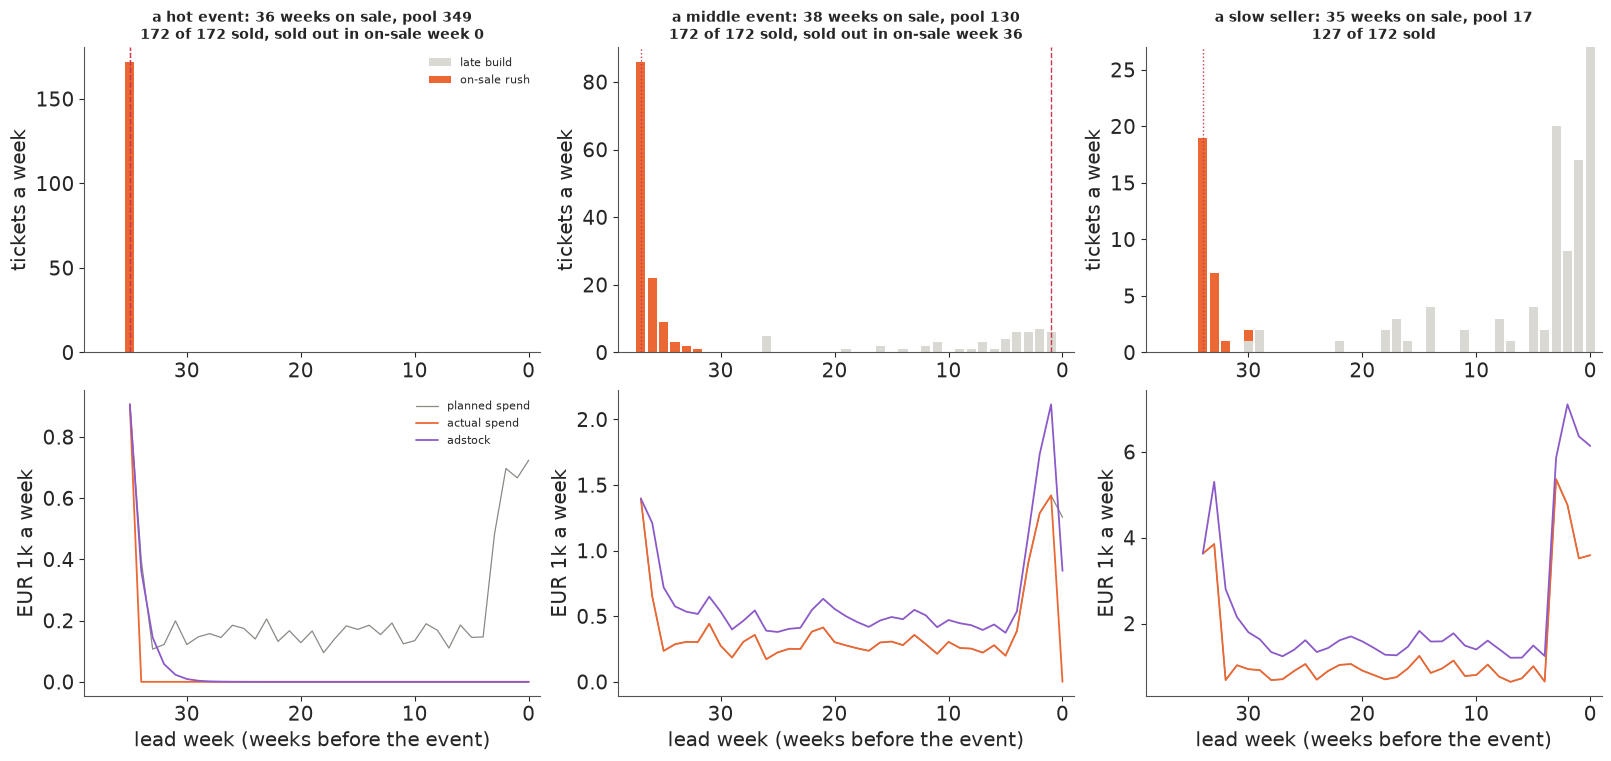

In [6]:
ev_d, plan_d = world(1, policy="rescue")
D_d = simulate(ev_d, plan_d, 4)
print(f"demo world: {D_d['sold'].mean():.0%} of events sell out, {np.mean(D_d['so_k'] == 0):.0%} in the on-sale week; "
      f"the rush is {D_d['rush_y'].sum() / D_d['y'].sum():.0%} of tickets sold")
print(f"capacity: City {ev_d['cap'][0]:.0f}, Resort {ev_d['cap'][-1]:.0f} tickets; correlation of log Q with the "
      f"log pool {np.corrcoef(ev_d['logQ'], np.log(ev_d['pool']))[0, 1]:.2f}; with log budget "
      f"{np.corrcoef(ev_d['logQ'], np.log(plan_d['B']))[0, 1]:.2f}")
kk_d = ev_d["n"][:, None] - 1 - LEADW[None, :]
fig, axes = plt.subplots(2, 3, figsize=(16, 7.5))
pick = [int(np.flatnonzero((D_d["so_k"] == 0) & (ev_d["n"] > 25))[0]),
        int(np.flatnonzero(D_d["sold"] & (D_d["so_k"] > 8) & (ev_d["n"] > 25))[0]),
        int(np.flatnonzero(~D_d["sold"] & (ev_d["v"] < -0.8) & (ev_d["n"] > 25))[0])]
for c, (e, lab) in enumerate(zip(pick, ["a hot event", "a middle event", "a slow seller"])):
    ax = axes[0, c]
    n_ = ev_d["n"][e]
    ax.bar(LEADW[:n_], D_d["y"][e, :n_] - D_d["rush_y"][e, :n_], color=LIGHT, label="late build")
    ax.bar(LEADW[:n_], D_d["rush_y"][e, :n_], bottom=D_d["y"][e, :n_] - D_d["rush_y"][e, :n_], color=ORANGE,
           label="on-sale rush")
    ax.axvline(n_ - 1, color=RED, lw=1, ls=":")
    if D_d["sold"][e]:
        ax.axvline(n_ - 1 - D_d["so_k"][e], color=RED, lw=1, ls="--")
    ax.set(xlim=(W, -1), ylabel="tickets a week")
    ax.set_title(f"{lab}: {n_} weeks on sale, pool {ev_d['pool'][e]:.0f}\n{D_d['total'][e]:.0f} of {ev_d['cap'][e]:.0f} "
                 "sold" + (f", sold out in on-sale week {D_d['so_k'][e]}" if D_d["sold"][e] else ""), fontsize=10)
    ax = axes[1, c]
    ax.plot(LEADW[:n_], plan_d["S"][e, :n_], color=MUTED, lw=0.9, label="planned spend")
    ax.plot(LEADW[:n_], D_d["spend"][e, :n_], color=ORANGE, lw=1.3, label="actual spend")
    ax.plot(LEADW[:n_], D_d["A"][e, :n_], color=PURPLE, lw=1.3, label="adstock")
    ax.set(xlim=(W, -1), xlabel="lead week (weeks before the event)", ylabel="EUR 1k a week")
axes[0, 0].legend(fontsize=8)
axes[1, 0].legend(fontsize=8);

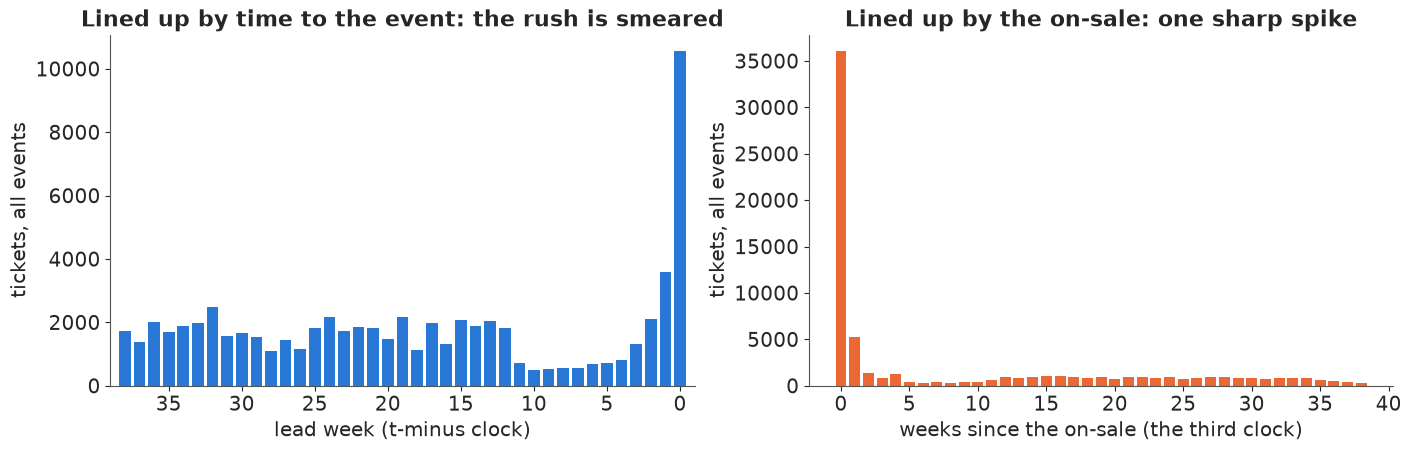

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
tot_l = D_d["y"].sum(0)
ax = axes[0]
ax.bar(LEADW, tot_l, color=BLUE)
ax.set(xlim=(W, -1), xlabel="lead week (t-minus clock)", ylabel="tickets, all events",
       title="Lined up by time to the event: the rush is smeared")
ax = axes[1]
kb = np.arange(W)
tot_k = np.array([D_d["y"][kk_d == k].sum() for k in kb])
ax.bar(kb, tot_k, color=ORANGE)
ax.set(xlabel="weeks since the on-sale (the third clock)", ylabel="tickets, all events",
       title="Lined up by the on-sale: one sharp spike");

In this world 44% of events sell out, 11% of all events already in the on-sale week
(a quarter of the sell-outs), and the rush is close to two thirds of all tickets sold. The queue
correlates 0.97 with the true log pool, and the rescue budget -0.80 with the queue. The hot event
(left) sells out in its first week and spend stops after the on-sale burst; the middle event's
rush takes a large bite and the late build fills the rest; the slow seller never fills. In the
second figure, lined up by lead time, the rush is smeared over leads 12 to 38 into a plateau of
about 2,000 tickets a week; lined up by weeks since the on-sale, it is one spike.

## C · The smeared spike

We need many fits, so as in E104 a fast stand-in comes first: Poisson maximum likelihood on the
weekly cells with free event effects, solved by L-BFGS on a sparse design, with the censored term
$P(Y \ge R)$ where a part needs it. Three models,

$$\begin{aligned}
\text{lead time only:}\quad & \log\mu_{el} = a_e + f(l) + \beta A_{el},\\
\text{three clocks, log-additive:}\quad & \log\mu_{el} = a_e + f(l) + h(k) + g(d)
  + \beta A_{el},\\
\text{pool:}\quad & \mu_{el} = \big[e^{a_e + f(l) + g(d)} + 1\{k < 6\}\, e^{b_e + h(k)}\big]
  \, e^{\beta A_{el}}.
\end{aligned}$$

The pool model is the world's own structure: a late build plus a six-week rush with its own level
$b_e$ for each event (a ridge of sd 2 keeps it finite for events whose rush is never seen). Parts
C to E use a constant true $\beta = 0.10$ and two simulated worlds per row. Part C has no
capacity, so nothing is censored yet. Its three worlds: windows of 3-9 months with the common
ramp; every window 26 weeks, so the clocks coincide; and varying windows with spend flat over the
window.

In [8]:
NKH = 6                                       # rush weeks 0-5 since the on-sale


def dummies(codes, n=None, drop_first=False):
    codes = np.asarray(codes)
    if n is None:
        _, codes = np.unique(codes, return_inverse=True)
        n = codes.max() + 1
    M = sp.csr_matrix((np.ones(len(codes)), (np.arange(len(codes)), codes)), shape=(len(codes), n))
    return M[:, 1:] if drop_first else M


BANDS = [(0, 3), (4, 11), (12, 38)]


def fit_fast(P, model="pool", beta="const", censor=True, event="fe", tau=(1.0, 1.0), mundlak=False, rows=None,
             b_ridge_sd=2.0, qcov=None, return_all=False):
    """Poisson ML on weekly cells (L-BFGS on a sparse design), censored sell-out weeks optional.
    'lead':   log mu = a_e + f(lead) + beta A
    '3clock': log mu = a_e + f(lead) + h(k) + g(cal) + beta A
    'pool':   mu = [exp(a_e + f(lead) + g(cal)) + 1{k < 6} exp(b_e + h(k))] e^{beta A}
    event 'fe' (free effects; a ridge of sd 2 on b_e) or 're' (Gaussian effects of sd tau: a posterior mode)."""
    r = np.ones(len(P["y"]), bool) if rows is None else rows
    y, A, ev, lead, k, cal = (P[c][r] for c in ("y", "A", "ev", "lead", "k", "cal"))
    c = P["cens"][r] if censor else np.zeros(len(y), bool)
    _, evi = np.unique(ev, return_inverse=True)
    nE = evi.max() + 1
    Bb = np.column_stack([((lead >= a) & (lead <= b)).astype(float) for a, b in BANDS]) if beta == "bands" \
        else np.ones((len(y), 1))
    Xb, kb = Bb * A[:, None], Bb.shape[1]
    blocks1 = [dummies(evi, nE), dummies(lead, W, drop_first=True)]
    if model == "3clock":
        blocks1.append(dummies(np.minimum(k, NKH), NKH + 1)[:, :NKH])
    if model in ("3clock", "pool"):
        blocks1.append(dummies(cal, cal.max() + 1, drop_first=True))
    if event == "re" or mundlak:
        M_ev = np.log(np.maximum(np.bincount(evi, weights=A, minlength=nE) / np.bincount(evi, minlength=nE), 1e-3))
        M_ev -= M_ev.mean()
    if event == "re":
        blocks1.append(sp.csr_matrix(np.ones((len(y), 1))))
        if mundlak:
            blocks1.append(sp.csr_matrix(M_ev[evi][:, None]))
    X1 = sp.hstack(blocks1).tocsr()
    n1 = X1.shape[1]
    pen1 = np.full(n1, 1e-3)
    pen1[:nE] = 1e-4 if event == "fe" else 0.5 / tau[0] ** 2
    if event == "re":
        pen1[n1 - 1 - int(mundlak):] = 0.0
    rr = k < NKH
    if model == "pool":
        blocks2 = [dummies(evi, nE), dummies(np.minimum(k, NKH - 1), NKH, drop_first=True),
                   sp.csr_matrix(np.ones((len(y), 1)))]
        if mundlak:
            blocks2.append(sp.csr_matrix(M_ev[evi][:, None]))
        if qcov is not None:
            blocks2.append(sp.csr_matrix(qcov[r][:, None]))
        X2 = (sp.diags(rr.astype(float)) @ sp.hstack(blocks2)).tocsr()
        n2 = X2.shape[1]
        pen2 = np.full(n2, 1e-3)
        pen2[:nE] = 0.5 / (b_ridge_sd if event == "fe" else tau[1]) ** 2
        pen2[nE + NKH - 1:] = 0.0
    else:
        X2, n2, pen2 = None, 0, np.zeros(0)
    X1T, X2T = X1.T.tocsr(), (X2.T.tocsr() if X2 is not None else None)
    yc, pen = y[c], np.concatenate([np.zeros(kb), pen1, pen2])

    def nll(th):
        m = np.exp(np.clip(Xb @ th[:kb], -20, 20))
        e1 = np.exp(np.clip(X1 @ th[kb:kb + n1], -30, 20))
        e2 = np.where(rr, np.exp(np.clip(X2 @ th[kb + n1:], -30, 20)), 0.0) if X2 is not None else 0.0
        mu = (e1 + e2) * m
        ll, gmu = y * np.log(mu) - mu, y / mu - 1.0
        if c.any():                                        # log P(Y >= R) and its derivative
            lsf = stats.poisson.logsf(yc - 1, mu[c])
            with np.errstate(all="ignore"):
                hz = np.exp(stats.poisson.logpmf(yc - 1, mu[c]) - lsf)
            ll[c], gmu[c] = lsf, np.where(np.isfinite(hz), hz, yc / mu[c] - 1.0)
        g = [Xb.T @ (gmu * mu), X1T @ (gmu * e1 * m)] + ([X2T @ (gmu * e2 * m)] if X2 is not None else [])
        return -ll.sum() + (pen * th * th).sum(), -np.concatenate(g) + 2 * pen * th

    th0 = np.zeros(kb + n1 + n2)
    lm = np.log(np.bincount(evi, weights=y, minlength=nE) / np.bincount(evi, minlength=nE) + 0.1)
    if model == "pool":
        th0[kb:kb + nE] = lm - 1.0 - (lm.mean() if event == "re" else 0)
        th0[kb + n1:kb + n1 + nE] = lm + 0.5 - (lm + 0.5).mean()
        th0[kb + n1 + nE + NKH - 1] = (lm + 0.5).mean() - (np.mean(qcov[r]) if qcov is not None else 0.0)
        if qcov is not None:
            th0[-1] = 1.0
        th0[kb + n1 + nE:kb + n1 + nE + NKH - 1] = np.log(KER[1:] / KER[0])   # start at the real rush shape
    else:
        th0[kb:kb + nE] = lm - (lm.mean() if event == "re" else 0)
    if event == "re":
        th0[kb + n1 - 1 - int(mundlak)] = lm.mean() - (1.0 if model == "pool" else 0)
    res = minimize(nll, th0, jac=True, method="L-BFGS-B", options=dict(maxiter=20000, gtol=1e-6))
    if return_all:
        return dict(x=res.x, kb=kb, n1=n1, nE=nE, ev_u=np.unique(ev))
    return res.x[:kb] if kb > 1 else float(res.x[0])


def tau_from_fe(P, model):
    """Spread of the fixed effects: the sd for the random-effects fits."""
    o = fit_fast(P, model=model, return_all=True)
    kb, n1, nE = o["kb"], o["n1"], o["nE"]
    out = [np.std(o["x"][kb:kb + nE]), np.std(o["x"][kb + n1:kb + n1 + nE]) if model == "pool" else 1.0]
    return tuple(max(float(v), 0.1) for v in out)


def rush_hat(o, P, qcov=None):
    """Expected rush buyers per event at zero spend, from a 'pool' fit."""
    t2 = o["x"][o["kb"] + o["n1"]:]
    nE = o["nE"]
    eta = t2[:nE] + t2[nE + NKH - 1]
    if qcov is not None:
        _, first = np.unique(P["ev"], return_index=True)
        eta = eta + t2[-1] * qcov[first]
    return np.exp(eta) * (1 + np.exp(t2[nE:nE + NKH - 1]).sum())


R_REP = 2
SC = []


def rec(part, scen, est, val, truth):
    SC.append(dict(part=part, scenario=scen, estimator=est, value=val, truth=truth))


t0 = time.time()
for r in range(R_REP):
    for scen, wkw, flat in [("windows 3-9 months, common ramp", {}, False),
                            ("every window 26 weeks, common ramp", dict(n_lo=26, n_hi=26), False),
                            ("windows 3-9 months, even spend", {}, True)]:
        ev, plan = world(100 + r, **wkw)
        if flat:
            plan = dict(plan, S=plan["B"][:, None] * shape_matrix(ev, "even")
                        * np.random.default_rng(5).lognormal(-0.02, 0.2, (E, W)) * ev["in_win"])
        D = simulate(ev, plan, 200 + r, capped=False, stop=False, beta_kind="const")
        P = panel(ev, D)
        for m, lab in [("lead", "lead time only"), ("3clock", "three clocks, log-additive"), ("pool", "pool model")]:
            rec("C", scen, lab, fit_fast(P, model=m, censor=False), 0.10)
tab_c = pd.DataFrame(SC).groupby(["scenario", "estimator"], sort=False).value.agg(["mean", "min", "max"])
print(f"true beta 0.10 (no capacity); {R_REP} worlds per row, {time.time() - t0:.0f} s")
print(tab_c.round(3).to_string())

true beta 0.10 (no capacity); 2 worlds per row, 6 s
                                                                mean    min    max
scenario                           estimator                                      
windows 3-9 months, common ramp    lead time only              0.931  0.926  0.935
                                   three clocks, log-additive  0.118  0.105  0.130
                                   pool model                  0.095  0.093  0.097
every window 26 weeks, common ramp lead time only              0.091  0.091  0.091
                                   three clocks, log-additive  0.088  0.087  0.088
                                   pool model                  0.094  0.085  0.103
windows 3-9 months, even spend     lead time only             -2.184 -2.256 -2.113
                                   three clocks, log-additive  0.140  0.074  0.206
                                   pool model                  0.106  0.090  0.122


The lead-time model reads the rush as media: **$\beta = 0.93$ against a true 0.10**, nine times
the truth, in both worlds. The on-sale burst of the common ramp sits on top of the rush, and a
lead curve cannot hold a spike that comes at a different lead for every event. Give it equal
windows and the same model is right (0.091): the rush then always falls in the same lead week and
$f(l)$ absorbs it. That is the identification argument in practice: the third clock can be seen
only because windows differ, and once they do a model must have it.

With flat spend the lead-time model gives **-2.18**: adstock builds up over the first weeks while
the rush decays, so within each event more adstock goes with fewer sales. A smeared spike can push
the estimate anywhere.

An on-sale clock is necessary, but its log-additive form is not enough: 0.118 under the common
ramp, and under flat spend anywhere from 0.07 to 0.21 between the two worlds. It has one rush
shape relative to each event's level, while the real rush is a different multiple of the late
build in every event. Only the pool model, with a rush level $b_e$ per event, recovers the effect
(0.095 and 0.106).

## D · Instant sell-outs and the queue

Capacity and spend that stops at the sell-out now come in, with random budgets; a fifth of the
events sell out in their on-sale week. We fit the pool model keeping every week of the window;
dropping the weeks after a sell-out and censoring the sell-out week, E104's fix; and dropping the
instant sell-outs as well. Then we ask what each fit says about the **demand** of the instant
sell-outs, which is what a promoter deciding on a second date needs. Without the queue the rush
levels get a ridge of sd 1; with it, the rush level is $b_e = \theta_0 + \theta_1 \log Q_e + u_e$,
with a tighter ridge (sd 0.35) on $u_e$.

In [9]:
t0 = time.time()
dem = []
for r in range(R_REP):
    ev, plan = world(300 + r)
    D = simulate(ev, plan, 400 + r, capped=True, stop=True, beta_kind="const")
    Pall = panel(ev, D, mask=ev["in_win"])                       # every week of the window, sold out or not
    P = panel(ev, D)
    inst = D["so_k"] == 0
    scn = "capacity, spend stops at sell-out"
    rec("D", scn, "every week kept, no censoring", fit_fast(Pall, censor=False), 0.10)
    rec("D", scn, "weeks after the sell-out dropped, sell-out week censored", fit_fast(P), 0.10)
    rec("D", scn, "... and the instant sell-outs dropped", fit_fast(P, rows=~inst[P["ev"]]), 0.10)
    q = ev["logQ"][P["ev"]]
    for lab, kw in [("no queue signal", dict(b_ridge_sd=1.0)), ("queue as a covariate", dict(b_ridge_sd=0.35, qcov=q))]:
        o = fit_fast(P, return_all=True, **kw)
        ratio = rush_hat(o, P, qcov=kw.get("qcov")) / ev["pool"][o["ev_u"]]
        ii = inst[o["ev_u"]]
        dem.append(dict(world=r, model=lab, events="instant sell-outs", median_ratio=np.median(ratio[ii]),
                        median_abs_log_error=np.median(np.abs(np.log(ratio[ii])))))
        dem.append(dict(world=r, model=lab, events="the rest", median_ratio=np.median(ratio[~ii]),
                        median_abs_log_error=np.median(np.abs(np.log(ratio[~ii])))))
    sold6 = (D["y"] * ((ev["n"][:, None] - 1 - LEADW[None, :]) < 6)).sum(1)
    dem.append(dict(world=r, model="tickets sold = demand", events="instant sell-outs",
                    median_ratio=np.median(sold6[inst] / ev["pool"][inst]),
                    median_abs_log_error=np.median(np.abs(np.log(sold6[inst] / ev["pool"][inst])))))
    print(f"world {r}: {D['sold'].mean():.0%} sell out, {inst.mean():.0%} in the on-sale week")
tab_d = pd.DataFrame([s for s in SC if s["part"] == "D"]).groupby("estimator", sort=False).value.agg(["mean", "min", "max"])
print(f"true beta 0.10; {time.time() - t0:.0f} s")
print(tab_d.round(3).to_string())
print("estimated over true pool (demand) per event, median over events, mean of the worlds:")
print(pd.DataFrame(dem).groupby(["events", "model"], sort=False)[["median_ratio", "median_abs_log_error"]].mean()
      .round(2).to_string())

world 0: 42% sell out, 20% in the on-sale week


world 1: 44% sell out, 20% in the on-sale week
true beta 0.10; 18 s
                                                           mean    min    max
estimator                                                                    
every week kept, no censoring                             0.411  0.410  0.411
weeks after the sell-out dropped, sell-out week censored  0.108  0.102  0.114
... and the instant sell-outs dropped                     0.107  0.100  0.115
estimated over true pool (demand) per event, median over events, mean of the worlds:
                                         median_ratio  median_abs_log_error
events            model                                                    
instant sell-outs no queue signal                0.19                  1.65
the rest          no queue signal                0.98                  0.12
instant sell-outs queue as a covariate           0.85                  0.21
the rest          queue as a covariate           0.99                  0.10
i

Keeping every week gives **0.41**, E104's stop-at-sell-out trap, four times the
truth here; censoring brings it to 0.108. Dropping the instant sell-outs as well changes nothing
(0.107), and that is their lesson: **they carry no information about media**. An instant sell-out
contributes one censored week, "at least $R$", to a model with a free rush level of its own, and
any large enough rush level fits it, whatever $\beta$ is. Leaving them out does not bias a common
effect here, because the effect is the same for every event; if hot events responded differently,
the estimate would describe only the events that did not sell out at once.

They carry little information about **demand** either. Without the queue the pool model puts their
demand at a fifth of the truth (median ratio 0.19, a typical error on the log scale of 1.65, a
factor of five): the ridge pulls every unseen rush toward the mean. Counting tickets sold as
demand is less wrong (0.72), only because these events sold out by a modest margin. With the queue
as a covariate the estimate is 0.85 of the truth, with a typical log error of 0.21. For the other
events both versions are within a few per cent. The queue is the only thing here that looks at
demand above capacity; resale prices, waitlists and presale registrations can play the same part,
each a noisy measurement of the latent pool, which is how part F uses the queue.

## E · Who gets the money

### E1 · Rescue budgets and the sign flip

E104's trap was big events getting big budgets. Concert marketing often does the opposite: a show
that sells out at release needs no advertising and a slow seller gets a rescue budget. Here
budgets fall with the queue, $B_e \propto
e^{-0.6(\log Q_e - \overline{\log Q})}$. The walk-up tilt is off in this part, so that only the
budget rule is at work. Random effects get a Gaussian penalty with the spread of the same model's
fixed effects, and the Mundlak term is each event's log mean adstock, in both levels of the pool
model.

### E2 · Pre-sale spend

The announcement campaign moves the pool before a ticket is sold, so its effect sits inside each
event's rush level $b_e$, and its natural yardstick is the queue. We regress $\log Q_e$ on
pre-sale spend $P_e$, once with random pre-sale budgets and once with the big tours getting the
announcement money.

In [10]:
t0 = time.time()
cor = []
for r in range(R_REP):
    ev, plan = world(500 + r, policy="rescue")
    D = simulate(ev, plan, 600 + r, capped=True, stop=True, beta_kind="const", tilt=0.0)
    P = panel(ev, D)
    cor.append(np.corrcoef(np.log(plan["B"]), np.log(ev["pool"]))[0, 1])
    scn = "rescue budgets: hot events get little"
    tau = tau_from_fe(P, "pool")
    rec("E", scn, "pool model, fixed effects", fit_fast(P), 0.10)
    rec("E", scn, "pool model, random effects", fit_fast(P, event="re", tau=tau), 0.10)
    rec("E", scn, "pool model, random effects + Mundlak", fit_fast(P, event="re", tau=tau, mundlak=True), 0.10)
    rec("E", scn, "three clocks, fixed effects", fit_fast(P, model="3clock"), 0.10)
    rec("E", scn, "three clocks, random effects + Mundlak", fit_fast(P, model="3clock", event="re",
                                                                     tau=tau_from_fe(P, "3clock"), mundlak=True), 0.10)
    for pre in ("random", "hot"):
        ev, _ = world(900 + r, pre=pre)
        g_q = np.polyfit(ev["P"], ev["logQ"], 1)[0]
        rec("E", f"pre-sale spend: {pre}", "log queue on pre-sale spend", g_q, GAMMA)
        cor.append(np.corrcoef(ev["P"], ev["v"])[0, 1]) if pre == "hot" else None
tab_e = pd.DataFrame([s for s in SC if s["part"] == "E"]).groupby(["scenario", "estimator"], sort=False
                                                                  ).value.agg(["mean", "min", "max"])
print(f"{time.time() - t0:.0f} s; correlation of log budget with log pool {np.mean(cor[0::2]):.2f}; of hot pre-sale "
      f"spend with popularity {np.mean(cor[1::2]):.2f}")
print(tab_e.round(3).to_string())

9 s; correlation of log budget with log pool -0.77; of hot pre-sale spend with popularity 0.87
                                                                               mean    min    max
scenario                              estimator                                                  
rescue budgets: hot events get little pool model, fixed effects               0.107  0.093  0.122
                                      pool model, random effects              0.033 -0.002  0.067
                                      pool model, random effects + Mundlak    0.107  0.093  0.121
                                      three clocks, fixed effects             0.079  0.065  0.092
                                      three clocks, random effects + Mundlak  0.061  0.059  0.063
pre-sale spend: random                log queue on pre-sale spend             0.077  0.067  0.087
pre-sale spend: hot                   log queue on pre-sale spend             0.768  0.757  0.779


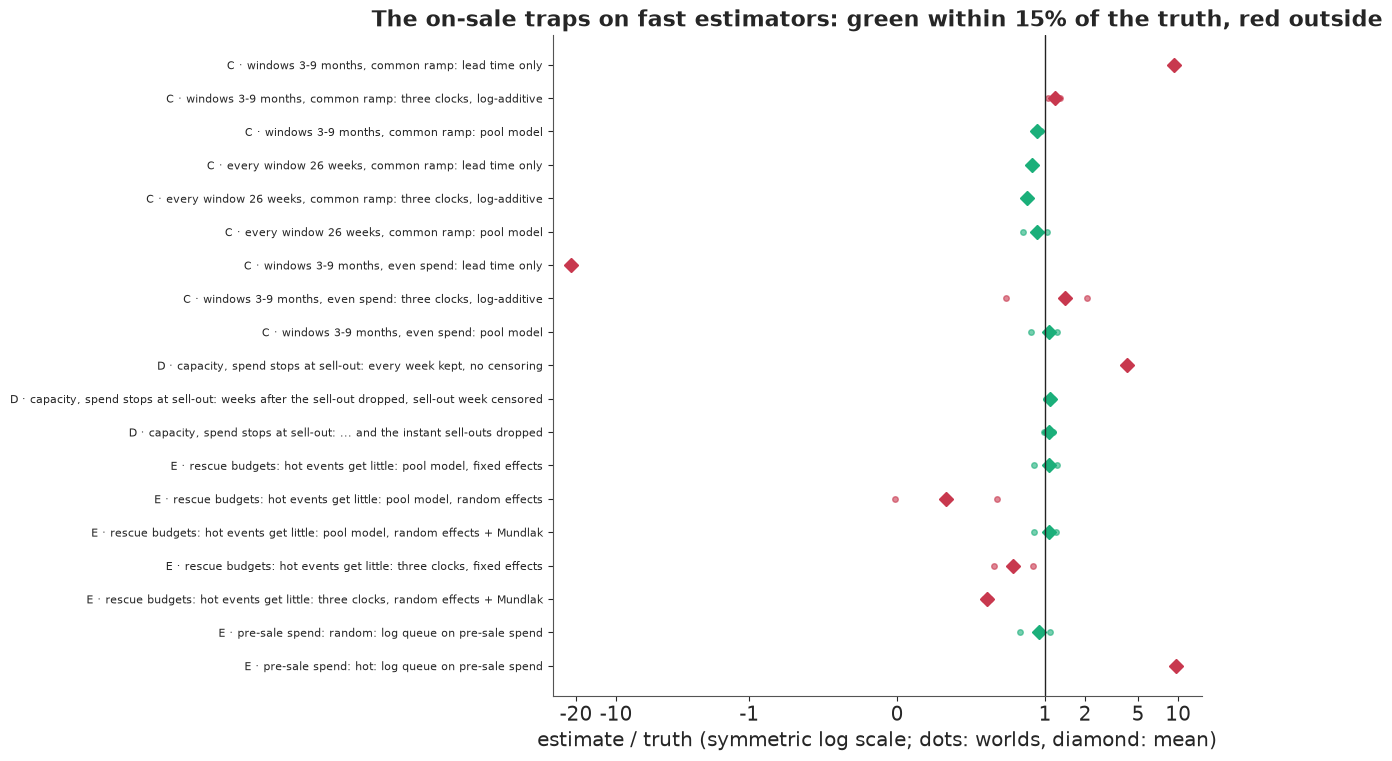

In [11]:
SCt = pd.DataFrame(SC)
SCt["rel"] = SCt.value / SCt.truth
agg = SCt.groupby(["part", "scenario", "estimator"], sort=False).rel.agg(["mean", "min", "max"])
fig, ax = plt.subplots(figsize=(12, 7.5))
ylab = []
for i, ((part, scn, est), row) in enumerate(agg.iterrows()):
    ok = abs(row["mean"] - 1) < 0.15
    col = AQUA if ok else RED
    vals = SCt[(SCt.scenario == scn) & (SCt.estimator == est)].rel
    ax.plot(vals, np.full(len(vals), -i), "o", color=col, ms=4, alpha=0.6)
    ax.plot(row["mean"], -i, "D", color=col, ms=7)
    ylab.append(f"{part} · {scn}: {est}")
ax.axvline(1, color=INK, lw=1)
ax.set_yticks(-np.arange(len(ylab)), ylab, fontsize=8)
ax.set_xscale("symlog", linthresh=1.0)
ax.set_xticks([-20, -10, -1, 0, 1, 2, 5, 10], ["-20", "-10", "-1", "0", "1", "2", "5", "10"])
ax.set(xlim=(-30, 15), xlabel="estimate / truth (symmetric log scale; dots: worlds, diamond: mean)",
       title="The on-sale traps on fast estimators: green within 15% of the truth, red outside");

Rescue budgets correlate -0.77 with the true pool, and the trap flips sign: **random effects give
0.033**, a third of the truth, against 0.107 for fixed effects. Events that got more money were
smaller; the random effects pull their levels toward the mean, and the negative slope across
events leaks into $\beta$. The Mundlak term restores the fixed-effects answer (0.107). The
log-additive three-clock model stays low (0.079 with fixed effects, 0.061 with random effects and
Mundlak): one rush shape relative to the event level cannot hold hot and slow events, and the
misfit lines up with the budget. That is misspecification, which Mundlak does not repair.

Random pre-sale budgets give $\gamma = 0.077$ against a true 0.08. When the big tours get the
money, the same regression gives **0.77**, ten times the truth: pre-sale spend then correlates
0.87 with popularity, and nothing in the queue tells a big tour from a well-advertised one. Only
randomised pre-sale budgets, or a model of how the announcement budget was set, identify the
effect.

The figure collects parts C to E on one scale, estimate over truth, red where an estimator misses
by more than 15%.

## F · When does a euro work?

### F1 · The model

Now the true response depends on lead time, the walk-up tilt is back, and the world has a real
platform's habits: the common ramp, rescue budgets (log sd 0.2), reactive pacing, capacity, and
spend that stops at the sell-out. The question is the shape of $\beta(l)$. In PyMC,

$$\begin{aligned}
Y_{el} &\sim \text{NegBin}(\mu_{el}, \alpha_{\text{rush}}) \text{ if } k_{el} < 6, \quad
\text{NegBin}(\mu_{el}, \alpha_{\text{late}}) \text{ otherwise}; \qquad
Y_{el} \ge R_{el} \text{ in the sell-out week},\\
\mu_{el} &= \big[e^{a_e + f_{\text{hotel}}(l) + g(d)} + 1\{k_{el} < 6\}\, e^{b_e + h_k}\big]\,
  e^{\beta(l) A_{el}},\\
a_e &= \mu_{a,\text{hotel}} + c_q\, \tilde q_e + \sigma_a z_e, \qquad b_e \sim N(m_e, \sigma_b),
  \qquad m_e = \mu_{b,\text{hotel}} + \gamma P_e,\\
\tilde q_e &\sim N(q_0 + b_e, s_q), \qquad \beta(l) = \textstyle\sum_j B_j(l)\, w_j, \qquad
  w_{j+1} = w_j + \sigma_c \zeta_j.
\end{aligned}$$

The centred log queue $\tilde q_e$ enters twice: as a predictor of the late level, and as a
**measurement** of the rush level. Rescue budgets were set from the queue and noise alone, so
conditioning on the queue is the adjustment the budget rule calls for, but only to the extent
that the outcome model is right in the queue. Here it enters as a level shift, while the walk-up
tilt makes the shape of the late build depend on popularity: that path stays open until a
queue-by-lead term is added (the first exercise). (A Mundlak term next to the queue adds nothing
but a ridge, since the budget is a function of the queue.) Nor does the queue close the path
through reactive pacing, which scales each week's spend by the event's shortfall against target,
as in E104. The two hotels book on different curves (38% and 54% of bookings in the last four
weeks), and hotel also moves the queue and so the budget, so each hotel gets its own lead curve
$f_{\text{hotel}}$: a common zero-sum curve plus a zero-sum hotel deviation of sd $\sigma_f \sim$
HalfNormal(0.3), as E104 did by event type. The calendar effect $g$ is E104's detrended weekly
random walk; the rush shape has $h_0 = 0$ and $N(-1.5, 1.5)$ priors for weeks 1-5. $\beta(l)$ is
built from seven cubic B-splines with knots at lead weeks 0, 3, 9, 20 and 38, whose weights follow
a random walk from $c_0 \sim N(0.1, 0.15)$ with six steps of sd $\sigma_c \sim$ HalfNormal(0.05):
a smooth curve that shrinks toward a constant. The sell-out week uses `pm.Censored`, as in E104.
We sample with nutpie's default warm-up of 400 steps and `target_accept=0.9`, starting the scale
parameters at sensible values: from nutpie's jittered start, one chain of a development run stuck
at a log density 25,000 below the others.

Two failures shaped this model.

**Failure 1: the measurement written directly.** With $b_e = m_e + \sigma_b u_e$ and $\tilde q_e
\sim N(q_0 + b_e, s_q)$, a precise queue ties every $u_e$ to its data through $s_q$, and in
development that version had not finished after twelve minutes. The same joint distribution can be
written the other way round: the queue's marginal, $\tilde q_e \sim N(m_e + q_0, \sqrt{\sigma_b^2
+ s_q^2})$, then the rush level given the queue,

$$b_e = m_e + \frac{\sigma_b^2}{v}\big(\tilde q_e - q_0 - m_e\big)
  + \frac{\sigma_b\, s_q}{\sqrt v}\, z_e,
\qquad v = \sigma_b^2 + s_q^2, \quad z_e \sim N(0, 1).$$

It is exact, the $z_e$ are well scaled whatever $s_q$ turns out to be, and the fits below take
about a minute each.

**Failure 2: one dispersion for two kinds of buyer.** The rush is Poisson given the pool; the
real late build is lumpy. With one negative-binomial shape for both, a development fit put the
queue's noise at 0.08 against a true 0.3: a dispersion set by the lumpy late weeks is far too
loose for the rush. Two dispersions, one for the six rush weeks and one for the rest, fixed it.

The observational data are 160 events of this world, 80 per hotel. First the prior.

In [12]:
KN = np.array([0, 0, 0, 0, 3, 9, 20, 38, 38, 38, 38], float)
BS = BSpline.design_matrix(np.arange(W, dtype=float), KN, 3).toarray()   # 7 cubic B-splines on lead weeks 0-38
BT = beta_true(LEADW)


def pool_model(ev, D, EV):
    """Censored negative-binomial pool model on the weekly cells of events EV."""
    e_, l_ = np.nonzero(D["live"][EV])
    ge = EV[e_]
    y, A, cen, rem = D["y"][ge, l_], D["A"][ge, l_], D["cens"][ge, l_], D["rem"][ge, l_]
    k_ = ev["n"][ge] - 1 - l_
    cal_u, cal_i = np.unique(CALW[ge, l_], return_inverse=True)
    ncal, nE = len(cal_u), len(EV)
    qc = ev["logQ"][EV] - ev["logQ"][EV].mean()
    Pc = ev["P"][EV] - ev["P"].mean()
    hot = HOTEL[EV]
    tt = np.arange(ncal) - (ncal - 1) / 2
    Qm = np.column_stack([np.ones(ncal), tt])
    PD = np.eye(ncal) - Qm @ np.linalg.pinv(Qm)                 # detrended calendar walk, as in E104
    unc, cc = np.flatnonzero(~cen), np.flatnonzero(cen)
    rr, kk = (k_ < NKH).astype(float), np.minimum(k_, NKH - 1)
    coords = dict(event=np.arange(nE), leadweek=LEADW, k=np.arange(1, NKH), calweek=np.arange(ncal),
                  step=np.arange(1, BS.shape[1]), hotel=HOTELS)
    with pm.Model(coords=coords) as m:
        mu_a = pm.Normal("mu_a", np.log(np.mean(y[k_ >= NKH]) + 0.1), 1.0, dims="hotel")
        c_aq = pm.Normal("c_aq", 0.0, 1.0)
        sd_a = pm.HalfNormal("sd_a", 0.5)
        z_a = pm.Normal("z_a", 0.0, 1.0, dims="event")
        a_ev = mu_a[hot] + c_aq * qc + sd_a * z_a
        curve0 = pm.ZeroSumNormal("curve0", 1.0, dims="leadweek")
        sd_hc = pm.HalfNormal("sd_hc", 0.3)                   # how far each hotel's curve strays from the common one
        z_hc = pm.ZeroSumNormal("z_hc", 1.0, dims=("hotel", "leadweek"), n_zerosum_axes=2)
        curve = pm.Deterministic("curve", curve0[None, :] + sd_hc * z_hc, dims=("hotel", "leadweek"))
        sd_cal = pm.HalfNormal("sd_cal", 0.2)
        cal_innov = pm.Normal("cal_innov", 0.0, 1.0, dims="calweek")
        calv = pt.dot(PD, pt.cumsum(cal_innov) * sd_cal)
        mu_b = pm.Normal("mu_b", np.log(np.mean(y[k_ == 0]) + 1), 1.5, dims="hotel")
        gamma = pm.Normal("gamma", 0.0, 0.5)
        sd_b = pm.HalfNormal("sd_b", 1.0)
        z_b = pm.Normal("z_b", 0.0, 1.0, dims="event")
        m_b = mu_b[hot] + gamma * Pc
        q0 = pm.Normal("q0", -np.log(np.mean(y[k_ == 0]) + 1), 1.5)
        s_q = pm.HalfNormal("s_q", 0.5)
        v_ = sd_b ** 2 + s_q ** 2                               # the queue's marginal, then b_e given the queue
        pm.Normal("logQ", m_b + q0, pt.sqrt(v_), observed=qc)
        b_ev = m_b + sd_b ** 2 / v_ * (qc - q0 - m_b) + sd_b * s_q / pt.sqrt(v_) * z_b
        h = pm.Normal("h", -1.5, 1.5, dims="k")
        hk = pt.concatenate([pt.zeros(1), h])
        c0 = pm.Normal("c0", 0.1, 0.15)
        sd_c = pm.HalfNormal("sd_c", 0.05)
        zc = pm.Normal("zc", 0.0, 1.0, dims="step")
        coef = c0 + pt.concatenate([pt.zeros(1), pt.cumsum(sd_c * zc)])   # a random walk over the spline weights
        beta_l = pm.Deterministic("beta_l", pt.dot(BS, coef), dims="leadweek")
        alpha_r = pm.Gamma("alpha_r", 2.0, 0.05)              # dispersion of the on-sale weeks
        alpha_l = pm.Gamma("alpha_l", 2.0, 0.2)               # ... and of the late build
        al_c = pt.switch(k_ < NKH, alpha_r, alpha_l)
        mu = (pt.exp(a_ev[e_] + curve[hot[e_], l_] + calv[cal_i]) + rr * pt.exp(b_ev[e_] + hk[kk])) * pt.exp(beta_l[l_] * A)
        pm.NegativeBinomial("y", mu=mu[unc], alpha=al_c[unc], observed=y[unc])
        pm.Censored("y_soldout", pm.NegativeBinomial.dist(mu=mu[cc], alpha=al_c[cc]), lower=None,
                    upper=rem[cc], observed=rem[cc])
    info = dict(y=y, k=k_, l=l_, e=e_, unc=unc, cc=cc, n_inst=int(np.sum(cen & (k_ == 0))), qmean=ev["logQ"][EV].mean(),
                Pmean=ev["P"].mean())
    return m, info


VARS = ["mu_a", "c_aq", "sd_a", "z_a", "curve0", "sd_hc", "z_hc", "sd_cal", "cal_innov", "mu_b", "gamma", "sd_b", "z_b", "q0", "s_q",
        "h", "c0", "sd_c", "zc", "alpha_r", "alpha_l", "beta_l"]


INIT = {"alpha_l": 1.2, "alpha_r": 50.0, "s_q": 0.3, "sd_b": 1.0, "sd_hc": 0.2}   # a sensible start for the scales


def fit_report(name, m, info, ev, D, EV, draws=1000):
    t0 = time.time()
    with m:
        idata = pm.sample(draws=draws, target_accept=0.9, random_seed=RANDOM_SEED, progressbar=False,
                          initvals=INIT)
    t = time.time() - t0
    st, po = idata.sample_stats, idata.posterior
    rh = {v: float(az.rhat(po[v]).max()) for v in VARS}
    es = min(min(float(az.ess(po[v], method=k).min()) for k in ("bulk", "tail")) for v in VARS)
    bl = po["beta_l"].to_numpy().reshape(-1, W)
    lo, hi = np.quantile(bl, [0.05, 0.95], axis=0)
    worst = sorted(rh, key=rh.get)[-3:][::-1]
    print(f"{name}: {len(EV)} events, {len(info['y']):,} event-weeks, {len(info['cc'])} censored sell-out weeks "
          f"({info['n_inst']} in the on-sale week); {t:.0f} s, {po.attrs.get('tuning_steps')} warm-up steps, "
          f"{int(st['diverging'].sum())} divergences, "
          f"max r_hat {max(rh.values()):.3f} ({', '.join(worst)}), min ESS {es:.0f}, max depth {int(st['depth'].max())}")
    print("   beta(lead week), mean (90% interval) against the truth: " + "; ".join(
        f"{l}: {bl[:, l].mean():.3f} ({lo[l]:.3f}-{hi[l]:.3f}) vs {BT[l]:.3f}" for l in (0, 2, 5, 10, 20)))
    print(f"   90% band covers the truth at {np.mean((lo <= BT) & (BT <= hi)):.0%} of lead weeks")
    for v in ("gamma", "c_aq", "sd_a", "sd_b", "s_q", "alpha_r", "alpha_l"):
        x = po[v].to_numpy().ravel()
        print(f"   {v}: {x.mean():.3f} ({np.quantile(x, 0.05):.3f}-{np.quantile(x, 0.95):.3f})", end="")
    print()
    sub = az.extract(idata, var_names=["mu_a", "c_aq", "sd_a", "mu_b", "gamma", "sd_b", "q0", "s_q", "h", "curve",
                                       "alpha_r", "alpha_l", "beta_l"], num_samples=400, random_seed=1)
    post = {v: sub[v].values for v in sub.data_vars}
    post.update(beta_draws=post.pop("beta_l"), qmean=info["qmean"], Pmean=info["Pmean"])
    return idata, post, bl


# observational world: common ramp, rescue budgets, reactive pacing, the walk-up tilt
ev_o, plan_o = world(700, policy="rescue", budget_sd=0.2, week_sd=0.05)
D_o = simulate(ev_o, plan_o, 800, reactive=True)
rs_ = np.random.default_rng(7)
EV_O = np.sort(np.concatenate([rs_.choice(np.flatnonzero(HOTEL == h), 80, replace=False) for h in (0, 1)]))
m_obs, info_o = pool_model(ev_o, D_o, EV_O)
with m_obs:
    prior = pm.sample_prior_predictive(300, random_seed=RANDOM_SEED)
pb = prior.prior["beta_l"].to_numpy().reshape(-1, W)
pp_y = prior.prior_predictive["y"].to_numpy().reshape(300, -1)
print("prior beta(lead 0) 5/50/95%: " + " / ".join(f"{v:.2f}" for v in np.percentile(pb[:, 0], [5, 50, 95]))
      + "; beta(lead 20): " + " / ".join(f"{v:.2f}" for v in np.percentile(pb[:, 20], [5, 50, 95])))
print("prior predictive weekly tickets (uncensored weeks) 5/50/95%: " + " / ".join(
    f"{v:,.0f}" for v in np.percentile(pp_y, [5, 50, 95])) + "; observed " + " / ".join(
    f"{v:.0f}" for v in np.percentile(info_o["y"][info_o["unc"]], [5, 50, 95])))

prior beta(lead 0) 5/50/95%: -0.15 / 0.12 / 0.37; beta(lead 20): -0.19 / 0.10 / 0.40
prior predictive weekly tickets (uncensored weeks) 5/50/95%: 0 / 6 / 273; observed 0 / 1 / 19


In [13]:
idata_o, post_o, bl_o = fit_report("observational", m_obs, info_o, ev_o, D_o, EV_O)

observational: 160 events, 3,383 event-weeks, 70 censored sell-out weeks (18 in the on-sale week); 74 s, 400 warm-up steps, 1 divergences, max r_hat 1.025 (sd_c, zc, curve0), min ESS 181, max depth 8
   beta(lead week), mean (90% interval) against the truth: 0: 0.314 (0.245-0.383) vs 0.200; 2: 0.167 (0.140-0.195) vs 0.144; 5: 0.086 (0.052-0.120) vs 0.093; 10: 0.016 (-0.016-0.047) vs 0.053; 20: 0.017 (-0.004-0.038) vs 0.033
   90% band covers the truth at 69% of lead weeks
   gamma: 0.114 (-0.042-0.268)   c_aq: 0.210 (0.101-0.322)   sd_a: 0.540 (0.450-0.637)   sd_b: 1.117 (1.012-1.233)   s_q: 0.296 (0.253-0.342)   alpha_r: 64.740 (33.556-116.754)   alpha_l: 1.148 (1.020-1.289)


The prior puts $\beta$ at lead 0 between -0.15 and 0.37 (5-95%), and much the same at lead 20: no
view on timing, and room for media to hurt. Prior weekly sales reach 270 at the 95th percentile
against an observed 19: broad, not absurd.

Sampling takes a little over a minute, with one divergence, r_hat at most 1.03 and at least 181
effective draws (bulk and tail, every parameter); the deepest trees have depth 8. A healthy
posterior, and wrong where it matters. **$\beta$ in the final week is 0.31 (90% interval
0.25-0.38) against a true 0.20**, and ten weeks out 0.02 (-0.02 to 0.05) against 0.05: the
posterior says late money works half as well again as it does and early money hardly at all, and
its 90% band misses the truth at a third of lead weeks. The rest of the model is good: the rush
shape matches the real kernel (next figure), the queue's noise comes out at 0.30 (0.25-0.34), the
simulated value, and the pre-sale effect $\gamma$ at 0.11, with an interval from -0.04 to 0.27
around the true 0.08.

We do not know for sure where the bias comes from, and there are two suspects. The first is the
walk-up tilt: slow sellers sell relatively more in their last weeks, rescue budgets give them more
money, and the common ramp puts much of it in the last weeks. The hotel curves cannot absorb a
shape that differs with popularity inside a hotel, so what the model cannot fit lines up with
final-week spend, and the posterior credits media with it: E104's curve-timed problem, with curves
that differ the way budgets do. The second suspect is reactive pacing, which also sends
money to the slow sellers' last weeks. The next fit is some evidence on which one matters, and the
first exercise separates them.

### F2 · A timing experiment

The planner's instinct is to randomise the **timing**: a random 30% of events get a random shape -
front-loaded, back-loaded, pulsed or even - at the budget they would have had anyway, and hold
it: pacing keeps running on the other events, but an experiment event spends what it was
assigned. We fit the 215 experiment events on their own, with 700 draws to save time, since only
their band is compared.

In [14]:
ev_t, plan_t = world(700, policy="rescue", budget_sd=0.2, week_sd=0.05, exp_share=0.3)
D_t = simulate(ev_t, plan_t, 800, reactive=plan_t["shape"] == "common ramp")   # experiment events hold their schedule
EV_T = np.flatnonzero(plan_t["shape"] != "common ramp")
m_tim, info_t = pool_model(ev_t, D_t, EV_T)
idata_t, post_t, bl_t = fit_report("timing-only experiment, its events alone", m_tim, info_t, ev_t, D_t, EV_T, draws=700)
del idata_t, post_t

timing-only experiment, its events alone: 215 events, 4,376 event-weeks, 80 censored sell-out weeks (21 in the on-sale week); 52 s, 400 warm-up steps, 0 divergences, max r_hat 1.032 (mu_a, curve0, zc), min ESS 118, max depth 6
   beta(lead week), mean (90% interval) against the truth: 0: 0.243 (0.197-0.289) vs 0.200; 2: 0.175 (0.147-0.206) vs 0.144; 5: 0.098 (0.066-0.132) vs 0.093; 10: 0.041 (0.006-0.077) vs 0.053; 20: 0.025 (-0.003-0.053) vs 0.033
   90% band covers the truth at 95% of lead weeks
   gamma: 0.135 (0.016-0.255)   c_aq: 0.257 (0.165-0.349)   sd_a: 0.475 (0.409-0.545)   sd_b: 1.027 (0.946-1.115)   s_q: 0.301 (0.266-0.338)   alpha_r: 61.536 (34.771-103.433)   alpha_l: 1.521 (1.359-1.700)


The fit has no divergences, r_hat up to 1.03 and as few as 118 effective draws, thin but usable for
a band. It helps, but not where it matters most. **$\beta$ at lead 0 is 0.24 (0.20-0.29)** against
0.20, and at lead 2 0.175 (0.15-0.21) against 0.144: the band misses the truth at lead 2 and only
just covers it at lead 0. With about a hundred effective draws the ends of a band move in the
second decimal, so the fair reading is that the last weeks are biased high, by less than before.
These events held their schedules, so pacing played no part in their spend, and the bias is still
there: that points to the budget level, set by the rescue rule, together with the tilt. Spend now
moves between early and late weeks at random within each event, but across events the slow
sellers' last weeks still get more money, right where the tilt is.

### F3 · Randomise the budget too

In the second design the experiment events also get a **random budget**, independent of the queue:
the same world, the same seeds, the same 30% of events with the same shapes, and the same budgets
and weekly noise for everyone else. We also check what was actually spent, not only what was
planned: the correlation of log spend in the last four weeks with the queue and with popularity,
over the events still on sale then.

In [15]:
ev_x, plan_x = world(700, policy="rescue", budget_sd=0.2, week_sd=0.05, exp_share=0.3, exp_budget=True)
D_x = simulate(ev_x, plan_x, 800, reactive=plan_x["shape"] == "common ramp")
EV_X = np.flatnonzero(plan_x["shape"] != "common ramp")
print("experiment events by shape: " + ", ".join(f"{s} {np.sum(plan_x['shape'] == s)}" for s in SHAPES[1:]))
print(f"correlation of log budget with log Q: observational events {np.corrcoef(np.log(plan_o['B']), ev_o['logQ'])[0, 1]:.2f}, "
      f"experiment events {np.corrcoef(np.log(plan_x['B'][EV_X]), ev_x['logQ'][EV_X])[0, 1]:.2f}")


def late_spend_cor(ev, plan, D, EV):
    """Mean log spend in the live weeks of the last four, planned and as spent, against log Q and popularity."""
    e2 = EV[D["live"][EV, :4].any(1)]
    out = []
    for S_ in (plan["S"], D["spend"]):
        ls = np.array([np.log(S_[e, :4][D["live"][e, :4]].mean()) for e in e2])
        out += [np.corrcoef(ls, ev["logQ"][e2])[0, 1], np.corrcoef(ls, ev["v"][e2])[0, 1]]
    return len(e2), out


print("last four weeks, correlation of log spend with log Q / with popularity v, planned and as spent:")
for nm, ev_, plan_, D_, EV_ in [("observational, paced", ev_o, plan_o, D_o, EV_O), ("timing only", ev_t, plan_t, D_t, EV_T),
                                ("timing + budget", ev_x, plan_x, D_x, EV_X)]:
    n_, c_ = late_spend_cor(ev_, plan_, D_, EV_)
    print(f"   {nm} ({n_} events still on sale): planned {c_[0]:.2f} / {c_[1]:.2f}, spent {c_[2]:.2f} / {c_[3]:.2f}")
n_, c_ = late_spend_cor(ev_x, plan_x, simulate(ev_x, plan_x, 800, reactive=True), EV_X)
print(f"   timing + budget, had pacing run on the experiment events too: spent {c_[2]:.2f} / {c_[3]:.2f}")
m_exp, info_x = pool_model(ev_x, D_x, EV_X)
idata_x, post_x, bl_x = fit_report("timing + budget experiment, its events alone", m_exp, info_x, ev_x, D_x, EV_X)

experiment events by shape: front-loaded 47, back-loaded 64, pulsed 58, even 46
correlation of log budget with log Q: observational events -0.96, experiment events 0.03
last four weeks, correlation of log spend with log Q / with popularity v, planned and as spent:
   observational, paced (123 events still on sale): planned -0.93 / -0.84, spent -0.75 / -0.75
   timing only (162 events still on sale): planned -0.51 / -0.47, spent -0.51 / -0.47
   timing + budget (159 events still on sale): planned -0.07 / -0.10, spent -0.07 / -0.10
   timing + budget, had pacing run on the experiment events too: spent -0.22 / -0.30


timing + budget experiment, its events alone: 215 events, 4,324 event-weeks, 78 censored sell-out weeks (27 in the on-sale week); 62 s, 400 warm-up steps, 1 divergences, max r_hat 1.024 (curve0, zc, beta_l), min ESS 128, max depth 7
   beta(lead week), mean (90% interval) against the truth: 0: 0.220 (0.170-0.273) vs 0.200; 2: 0.160 (0.126-0.193) vs 0.144; 5: 0.102 (0.064-0.138) vs 0.093; 10: 0.064 (0.031-0.095) vs 0.053; 20: 0.037 (0.013-0.062) vs 0.033
   90% band covers the truth at 100% of lead weeks
   gamma: 0.135 (0.010-0.260)   c_aq: 0.192 (0.113-0.271)   sd_a: 0.441 (0.377-0.509)   sd_b: 1.045 (0.960-1.138)   s_q: 0.289 (0.254-0.326)   alpha_r: 62.309 (33.689-106.346)   alpha_l: 1.537 (1.367-1.726)


width of the 90% band of beta(l), mean over lead weeks: prior 0.58, timing + budget posterior 0.063
a unit spent at lead l, summed log-lift over the weeks it acts, truth (timing + budget posterior mean): 0: 0.200 (0.220); 1: 0.249 (0.276); 2: 0.244 (0.270); 5: 0.170 (0.188); 10: 0.095 (0.112); 20: 0.056 (0.063)


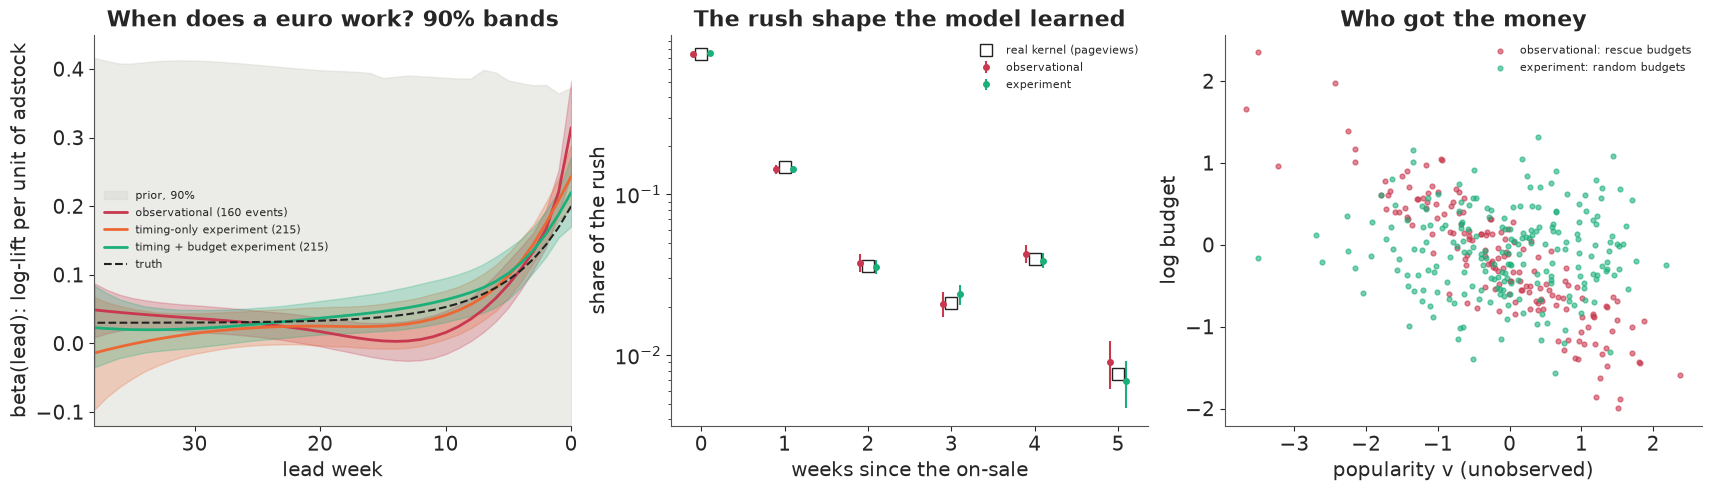

In [16]:
plo, phi_ = np.quantile(pb, [0.05, 0.95], axis=0)
xlo, xhi = np.quantile(bl_x, [0.05, 0.95], axis=0)
print(f"width of the 90% band of beta(l), mean over lead weeks: prior {np.mean(phi_ - plo):.2f}, "
      f"timing + budget posterior {np.mean(xhi - xlo):.3f}")


def carry_value(b):
    """Log-lift a unit spent at lead l adds over the weeks it acts: sum over l' <= l of beta(l') ALPHA^(l - l')."""
    return np.stack([sum(b[..., j] * ALPHA ** (l - j) for j in range(l + 1)) for l in range(W)], -1)


cv_t, cv_x = carry_value(BT), carry_value(bl_x)
print("a unit spent at lead l, summed log-lift over the weeks it acts, truth (timing + budget posterior mean): "
      + "; ".join(f"{l}: {cv_t[l]:.3f} ({cv_x[:, l].mean():.3f})" for l in (0, 1, 2, 5, 10, 20)))
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
ax = axes[0]
ax.fill_between(LEADW, plo, phi_, color=LIGHT, alpha=0.5, label="prior, 90%")
for bl, col, lab in [(bl_o, RED, f"observational ({len(EV_O)} events)"), (bl_t, ORANGE, f"timing-only experiment ({len(EV_T)})"),
                     (bl_x, AQUA, f"timing + budget experiment ({len(EV_X)})")]:
    ax.fill_between(LEADW, *np.quantile(bl, [0.05, 0.95], axis=0), color=col, alpha=0.25)
    ax.plot(LEADW, bl.mean(0), color=col, lw=2, label=lab)
ax.plot(LEADW, BT, color=INK, lw=1.5, ls="--", label="truth")
ax.set(xlim=(W - 1, 0), ylim=(-0.12, 0.45), xlabel="lead week", ylabel="beta(lead): log-lift per unit of adstock",
       title="When does a euro work? 90% bands")
ax.legend(fontsize=8)
ax = axes[1]
for nm, idata_, col in [("observational", idata_o, RED), ("experiment", idata_x, AQUA)]:
    hh = idata_.posterior["h"].to_numpy().reshape(-1, NKH - 1)
    sh = np.exp(np.column_stack([np.zeros(len(hh)), hh]))
    sh /= sh.sum(1, keepdims=True)
    ax.errorbar(np.arange(NKH) + (0.1 if nm == "experiment" else -0.1), sh.mean(0),
                yerr=np.abs(np.quantile(sh, [0.05, 0.95], axis=0) - sh.mean(0)), fmt="o", color=col, ms=4, label=nm)
ax.plot(np.arange(NKH), KER, "s", color=INK, mfc="none", ms=8, label="real kernel (pageviews)")
ax.set(yscale="log", xlabel="weeks since the on-sale", ylabel="share of the rush", title="The rush shape the model learned")
ax.legend(fontsize=8)
ax = axes[2]
lb = np.log(plan_o["B"][EV_O])
ax.scatter(ev_o["v"][EV_O], lb, s=12, color=RED, alpha=0.6, label="observational: rescue budgets")
ax.scatter(ev_x["v"][EV_X], np.log(plan_x["B"][EV_X]), s=12, color=AQUA, alpha=0.6, label="experiment: random budgets")
ax.set(xlabel="popularity v (unobserved)", ylabel="log budget", title="Who got the money")
ax.legend(fontsize=8);

In the experiment events the budget is now unrelated to the queue (0.03, against -0.96 in the
observational events), and so is what they spent in the last four weeks: -0.07 with the queue and
-0.10 with popularity, against -0.75 in the paced observational world and about -0.5 in the
timing-only experiment. Had pacing run on these events too, the correlation with popularity would
have been -0.30: a randomised plan is not a randomised spend unless it is kept.

The fit is as healthy - one divergence, r_hat at most 1.02, at least 128 effective draws - and
**$\beta$ at lead 0 is 0.22 (0.17-0.27) against 0.20, with the 90% band covering the truth at
every lead week**: 0.102 at five weeks against 0.093, 0.064 at ten against 0.053, 0.037 at twenty
against 0.033. That is one world and one draw of the experiment, so "every week" is partly luck,
but the band is the data's: the prior's 90% band is 0.58 wide on average, the posterior's 0.06.
The left panel shows the three fits against the prior, the middle panel the rush shape the
observational and the timing-and-budget fits learned, close to the real kernel, and the right
panel the difference between the designs: who got the money.

$\beta(l)$ is the response to adstock present at lead $l$, not the value of money spent then. A
unit spent at lead $l$ adds $0.4^{l - l'}$ to the adstock of every later week $l'$, so its summed
log-lift is $\sum_{l' \le l} \beta(l')\, 0.4^{l - l'}$. In the planted world that is 0.20 in the
last week, 0.25 one week earlier, 0.17 at five weeks and 0.10 at ten, and the experiment's
posterior recovers the pattern (0.22, 0.28, 0.19, 0.11): money one or two weeks out buys the most,
because it also works in the final week. A sell-out cuts the sum off, and each week's lift scales
with the buyers that week holds.

The lesson for a platform is to randomise whatever the confounder rides on, here the budget level
as well as its timing, and to keep the assignment. Then analyse the experiment on its own, or use
it to calibrate the observational model as in E103; simply adding its rows to the observational
ones may bring the bias back (the second exercise).

### F4 · Predictive checks

We check the uncensored weeks of both fits: totals by on-sale week, and, for the last four weeks,
totals by third of the queue - the analyst's own measure of popularity, and the natural place to
look for booking curves that differ between hot and slow events - and, within the low and high
thirds, by hotel, since Resort events, with their smaller pools, crowd the low third.

In [17]:
def ppc_check(name, m, idata, info, ev, EV):
    """Replicated tickets in the uncensored weeks: by weeks since the on-sale, and in the last four weeks by
    tercile of the queue (the analyst's measure of popularity)."""
    with m:
        ppc = pm.sample_posterior_predictive(idata.isel(draw=slice(None, None, 10)), var_names=["y"],
                                             random_seed=RANDOM_SEED, progressbar=False)
    yrep = ppc.posterior_predictive["y"].to_numpy().reshape(-1, len(info["unc"]))
    u = info["unc"]
    yo, ko, lo_, eo = info["y"][u], info["k"][u], info["l"][u], info["e"][u]
    qv = ev["logQ"][EV]
    terc = np.digitize(qv, np.quantile(qv, [1 / 3, 2 / 3]))[eo]
    hot_o = HOTEL[EV][eo]
    inside = (yo >= np.percentile(yrep, 5, 0)) & (yo <= np.percentile(yrep, 95, 0))
    rows = []
    for lab, sel in ([("on-sale week", ko == 0), ("on-sale weeks 1-5", (ko >= 1) & (ko < NKH)), ("later weeks", ko >= NKH)]
                     + [(f"last 4 weeks, {t} third of the queue", (lo_ <= 3) & (terc == i))
                        for i, t in enumerate(["low", "middle", "high"])]
                     + [(f"last 4 weeks, {t} third, {HOTELS[h].split()[0]}", (lo_ <= 3) & (terc == i) & (hot_o == h))
                        for i, t in ((0, "low"), (2, "high")) for h in (0, 1)]):
        tr = yrep[:, sel].sum(1)
        rows.append({"cells": lab, "observed": yo[sel].sum(), "replicated 5%": np.percentile(tr, 5),
                     "50%": np.percentile(tr, 50), "95%": np.percentile(tr, 95)})
    print(f"{name}: {inside.mean():.0%} of uncensored event-weeks inside their 90% predictive interval")
    print(pd.DataFrame(rows).round(0).to_string(index=False))


ppc_check("observational fit", m_obs, idata_o, info_o, ev_o, EV_O)
ppc_check("experiment fit", m_exp, idata_x, info_x, ev_x, EV_X)

observational fit: 97% of uncensored event-weeks inside their 90% predictive interval
                                  cells  observed  replicated 5%    50%    95%
                           on-sale week    6070.0         5876.0 6139.0 6440.0
                      on-sale weeks 1-5    1828.0         1746.0 1859.0 1965.0
                            later weeks    5695.0         6190.0 7166.0 8914.0
   last 4 weeks, low third of the queue    2305.0         2180.0 2962.0 4413.0
last 4 weeks, middle third of the queue    1368.0         1504.0 1925.0 2487.0
  last 4 weeks, high third of the queue     397.0          401.0  572.0  798.0
          last 4 weeks, low third, City    1239.0          863.0 1126.0 1566.0
        last 4 weeks, low third, Resort    1066.0         1185.0 1796.0 3187.0
         last 4 weeks, high third, City     371.0          333.0  483.0  708.0
       last 4 weeks, high third, Resort      26.0           33.0   75.0  157.0


experiment fit: 97% of uncensored event-weeks inside their 90% predictive interval
                                  cells  observed  replicated 5%    50%    95%
                           on-sale week    8253.0         8088.0 8410.0 8742.0
                      on-sale weeks 1-5    2612.0         2534.0 2659.0 2778.0
                            later weeks    6398.0         6488.0 7028.0 7676.0
   last 4 weeks, low third of the queue    1983.0         1568.0 1855.0 2198.0
last 4 weeks, middle third of the queue    1591.0         1794.0 2108.0 2491.0
  last 4 weeks, high third of the queue     536.0          591.0  770.0 1010.0
          last 4 weeks, low third, City     889.0          628.0  793.0  994.0
        last 4 weeks, low third, Resort    1094.0          827.0 1056.0 1335.0
         last 4 weeks, high third, City     499.0          541.0  721.0  962.0
       last 4 weeks, high third, Resort      37.0           17.0   40.0   87.0


In both fits 97% of weekly counts fall inside their 90% intervals, more than 90%: the weekly
intervals are too wide, from the loose dispersion of the late build ($\alpha_{\text{late}}$ about
1.1-1.5), so the totals are the sharper check. The rush is reproduced: 6,070 on-sale-week tickets
in the observational fit against a replicated 5,880-6,440. The late build is not. Both fits expect
more tickets after the rush than the events delivered (5,695 against 6,190-8,910 in the
observational fit, 6,398 against 6,490-7,680 in the experiment fit): E104's over-prediction of the
real hotel baseline, whose weeks are emptier and lumpier than a negative binomial allows.

In the experiment fit the last four weeks of the low-queue third are on target (1,983 against
1,570-2,200), and so are both hotels within it, while the middle and high thirds are
over-predicted, the high third's City events included (499 against 540-960). A pattern by queue
within a hotel is what the walk-up tilt would leave, and the hotel curves cannot remove it. The
observational fit over-predicts the middle third (1,368 against 1,500-2,490), puts the high third
at the bottom edge of its band (397 against 401-798) and the low third inside, but its low-queue
Resort events are over-predicted (1,066 against 1,190-3,190). Its check flags a misfit without
saying clearly which of the suspects made it; a queue-by-lead-curve term is the obvious next model
(the first exercise).

## G · From posterior to plan

### G1 · Choose over the posterior, not at its mean

The marketing lead wants a schedule for each of 200 events of a fresh season (new windows,
popularity and queues on the same real arrival dates). Each has 48 candidate plans: extra pre-sale
spend of 0, 2 or 4, times either no in-window spend or one of the five shapes at a weekly level of
0.5, 1 or 2. The value of a plan is $\lambda \times \text{tickets} - \text{spend}$, in abstract
units: $\lambda$ is the number of units of spend one ticket's margin is worth, here 1, so gains
are counted in ticket margins.

The two parts of a plan are decided at different times, on different information. **Pre-sale**
money is committed at the announcement, before any queue exists, knowing only the hotel, the
window and the pre-sale spend already planned: each posterior draw takes the rush level from its
prior and the queue from the measurement model, and we take the best of the 48 plans on average.
**In-window** spend is chosen at the release from the 16 in-window options, given the queue, which
already holds the extra pre-sale spend. Plans are simulated forward with negative-binomial noise,
capacity and spend that stops at the sell-out. **Over the posterior** averages over 150 draws; the
**plug-in** sets every parameter and the event's levels at their posterior means and simulates
only the noise (40 times). To see what the order of decisions is worth, one more policy cheats and
chooses the pre-sale money from the release queue. The model's **promise** for each plan is scored
twice: on the draws and random numbers that chose it, and on fresh ones. The **truth** replays the
simulator 12 times for every event and plan, which also gives the habit's value (the common ramp
at level 1) and the oracle's best plan, an upper bound since it picks and scores on the same
replays.

In [18]:
LAM = 1.0                                     # ticket margin in units of spend (abstract units, see the prose)
PRE_OPTS = [0.0, 2.0, 4.0]
SHAPE_OPTS = [("none", 0.0)] + [(s, lv) for s in SHAPES for lv in (0.5, 1.0, 2.0)]
CANDS = [(p, s, lv) for p in PRE_OPTS for (s, lv) in SHAPE_OPTS]
NS = len(SHAPE_OPTS)
NDRAW = 150


def new_season(seed):
    ev = make_events(seed)
    return add_signal(ev, pre_spend(ev, seed + 1), seed + 2)


def sched(ev, idx, shape, lv):
    return np.zeros((len(idx), W)) if shape == "none" else lv * shape_matrix(ev, shape)[idx]


def event_draws(post, ev, idx, rs, plug=False, blind=False, dP=0.0, logq=None):
    """Per posterior draw, a new event's late level and rush level. Given its queue logq (by default the one in ev),
    with dP of extra pre-sale spend already in that queue; or, blind, before any queue exists: the queue is then
    drawn from the measurement model, and only the hotel, window and pre-sale spend are known."""
    sel = rs.choice(post["gamma"].shape[-1], NDRAW, replace=False)
    g = lambda k: post[k][..., sel]
    h = HOTEL[idx]
    Pc = ev["P"][idx] + dP - post["Pmean"]
    sb, sq = g("sd_b")[None], g("s_q")[None]
    m_b = g("mu_b")[h] + g("gamma")[None] * Pc[:, None]
    if blind:
        b_m = m_b
        b = m_b + sb * rs.normal(size=m_b.shape)
        qc_m, qc = m_b + g("q0")[None], b + g("q0")[None] + sq * rs.normal(size=m_b.shape)
    else:
        qc = qc_m = ((ev["logQ"][idx] if logq is None else logq) - post["qmean"])[:, None]
        prec = 1 / sb ** 2 + 1 / sq ** 2
        b_m = (m_b / sb ** 2 + (qc - g("q0")[None]) / sq ** 2) / prec
        b = b_m + np.sqrt(1 / prec) * rs.normal(size=b_m.shape)
    a_m = g("mu_a")[h] + g("c_aq")[None] * qc_m
    a = g("mu_a")[h] + g("c_aq")[None] * qc + g("sd_a")[None] * rs.normal(size=m_b.shape)
    out = dict(a=a, b=b, curve=g("curve")[h], h=g("h"), beta=post["beta_draws"][:, sel], alpha_r=g("alpha_r"),
               alpha_l=g("alpha_l"), gamma=g("gamma"))
    if plug:                                  # every parameter at its posterior mean, the event at its mean
        out = {k: (a_m if k == "a" else b_m if k == "b" else v).mean(-1, keepdims=True) for k, v in out.items()}
    return out


def mu_cells(dr, ev, idx, Ssch, dP=0.0):
    """Expected tickets per event, lead week and draw, and each cell's dispersion. dP: extra pre-sale spend
    (a number or one per event) whose effect the draws do not hold yet."""
    n = ev["n"][idx]
    kk = n[:, None] - 1 - LEADW[None, :]
    rm = ((kk >= 0) & (kk < NKH))[..., None]
    hk = np.concatenate([np.zeros((1, dr["h"].shape[1])), dr["h"]], 0)
    dPa = np.reshape(dP, (-1, 1, 1)) if np.ndim(dP) else dP
    rush = np.where(rm, np.exp(dr["b"][:, None, :] + dr["gamma"][None, None, :] * dPa + hk[np.clip(kk, 0, NKH - 1)]), 0.0)
    mu = (np.exp(dr["a"][:, None, :] + dr["curve"]) + rush) * np.exp(dr["beta"][None] * adstock_t(Ssch)[..., None])
    return mu * (LEADW[None, :] < n[:, None])[..., None], np.where(rm, dr["alpha_r"], dr["alpha_l"])


def play(mu_al, cap, Ssch, rs, mask=None):
    """Gamma-Poisson (negative binomial) weekly demand, cumulated to capacity; spend stops after the sell-out."""
    mu, al = mu_al
    m = rs.poisson(mu * rs.gamma(al, 1 / al)).astype(float)
    if mask is not None:
        m = m * mask[..., None]
    cum = np.cumsum(m[:, ::-1], 1)                             # time order
    before = np.concatenate([np.zeros((m.shape[0], 1, m.shape[2])), cum[:, :-1]], 1) < cap[:, None, None]
    return np.minimum(cum[:, -1], cap[:, None]), (Ssch[:, ::-1][..., None] * before).sum(1), cum[:, -1] >= cap[:, None]


def plan_values(dr, ev, idx, opts, reps, seed, dP=0.0):
    """Expected tickets - in-window spend of each in-window option, per event, and P(sell-out), with common
    random numbers across options."""
    vals, psold = np.zeros((len(idx), len(opts))), np.zeros((len(idx), len(opts)))
    for j, (s, lv) in enumerate(opts):
        rs_c = np.random.default_rng(seed)
        Ssch = sched(ev, idx, s, lv)
        mu = mu_cells(dr, ev, idx, Ssch, dP)
        for _ in range(reps):
            tk, spd, so = play(mu, ev["cap"][idx], Ssch, rs_c)
            vals[:, j] += (LAM * tk.mean(1) - spd.mean(1)) / reps
            psold[:, j] += so.mean(1) / reps
    return vals, psold


def choose(post, ev, idx, plug, seed, promise=False, peek=False):
    """Two decisions at two times. At the announcement, before any queue: the extra pre-sale spend, the best of
    the 48 plans for draws whose queue is still unknown. At the release, with the queue in (moved by that spend):
    the in-window plan. promise: the model's expected gain of the plan over no paid media, on the draws and
    random numbers that chose it and on fresh ones. peek: the pre-sale choice looks at the release queue, which
    does not exist yet when that money is committed."""
    reps = 40 if plug else 1
    dr0 = event_draws(post, ev, idx, np.random.default_rng(seed), plug=plug, blind=not peek)
    v0 = np.hstack([plan_values(dr0, ev, idx, SHAPE_OPTS, reps, seed + 1, dP)[0] - dP for dP in PRE_OPTS])
    ip = v0.argmax(1) // NS
    dPv = np.array(PRE_OPTS)[ip]
    logq = ev["logQ"][idx] + GAMMA * dPv                      # the queue the world shows at the release
    dr1 = event_draws(post, ev, idx, np.random.default_rng(seed + 2), plug=plug, dP=dPv, logq=logq)
    v1, ps1 = plan_values(dr1, ev, idx, SHAPE_OPTS, reps, seed + 3)
    jw = v1.argmax(1)
    ch, ar = ip * NS + jw, np.arange(len(idx))
    out = dict(ch=ch, psold=ps1[ar, jw])
    if promise:
        def gain(dr, v, sd):                                  # the plan against no media, no extra pre-sale spend
            v_none = plan_values(dr, ev, idx, SHAPE_OPTS[:1], reps, sd, -dPv)[0][:, 0]
            return (v[ar, jw] - dPv - v_none).sum()
        dr2 = event_draws(post, ev, idx, np.random.default_rng(seed + 4), plug=plug, dP=dPv, logq=logq)
        out.update(same=gain(dr1, v1, seed + 3), fresh=gain(dr2, plan_values(dr2, ev, idx, SHAPE_OPTS, reps, seed + 5)[0],
                                                             seed + 5))
    return out


def true_value(ev, idx, Ssch, dP, nrep=12, seed0=90_000):
    """The simulator itself (real late build, simulated rush) under schedule Ssch for events idx."""
    ev2 = dict(ev, pool=ev["pool"].copy())
    ev2["pool"][idx] = ev["pool0"][idx] * np.exp(GAMMA * (ev["P"][idx] + dP))
    Sf = np.zeros((E, W))
    Sf[idx] = Ssch
    tk, spd = np.zeros(len(idx)), np.zeros(len(idx))
    for r in range(nrep):
        D = simulate(ev2, dict(S=Sf), seed0 + r)
        tk += D["total"][idx] / nrep
        spd += D["spend"][idx].sum(1) / nrep
    return tk, spd + dP


t0 = time.time()
ev_n = new_season(2000)
NEV = 200
idx_n = np.sort(np.random.default_rng(3).choice(E, NEV, replace=False))
TV = np.zeros((NEV, len(CANDS)))
for j, (dP, s, lv) in enumerate(CANDS):
    tk, spd = true_value(ev_n, idx_n, sched(ev_n, idx_n, s, lv), dP)
    TV[:, j] = LAM * tk - spd
J0, JH = CANDS.index((0.0, "none", 0.0)), CANDS.index((0.0, "common ramp", 1.0))
base = TV[:, J0]
res = [dict(policy="habit: common ramp at level 1", **{"true gain": (TV[:, JH] - base).sum()}),
       dict(policy="oracle: the true best per event", **{"true gain": (TV.max(1) - base).sum()})]
CH = {}
for fit_nm, post, plug, peek in [("observational", post_o, False, False), ("observational", post_o, True, False),
                                 ("experiment", post_x, False, False), ("experiment", post_x, True, False),
                                 ("experiment", post_x, False, True)]:
    o_ = choose(post, ev_n, idx_n, plug, 11, promise=True, peek=peek)
    ch = o_["ch"]
    lab = (f"{'plug-in at the posterior mean' if plug else 'over posterior draws'}, {fit_nm} fit"
           + (", pre-sale from the release queue" if peek else ""))
    res.append({"policy": lab, "true gain": (TV[np.arange(NEV), ch] - base).sum(), "promised": o_["same"],
                "promised, fresh draws": o_["fresh"], "mean extra pre-sale": np.mean([CANDS[c][0] for c in ch]),
                "mean in-window level": np.mean([CANDS[c][2] for c in ch])})
    CH[lab] = (ch, o_["psold"])
print(f"{len(CANDS)} candidate schedules x {NEV} new events, truth from 12 replays each; {time.time() - t0:.0f} s")
print(pd.DataFrame(res).round(1).to_string(index=False))

48 candidate schedules x 200 new events, truth from 12 replays each; 39 s
                                                               policy  true gain  promised  promised, fresh draws  mean extra pre-sale  mean in-window level
                                        habit: common ramp at level 1    -1329.2       NaN                    NaN                  NaN                   NaN
                                      oracle: the true best per event     2800.0       NaN                    NaN                  NaN                   NaN
                              over posterior draws, observational fit     2057.4    3001.0                 3394.8                  4.0                   0.5
                     plug-in at the posterior mean, observational fit     2054.4    3741.7                 4155.9                  4.0                   0.7
                                 over posterior draws, experiment fit     2070.5    3032.8                 2640.5                  4.0       

The habit loses money: the common ramp at level 1 on every event is worth **-1,330** against no
paid media, because its on-sale burst goes to events whose fans would have bought anyway and it
keeps running on events that are nearly full. The oracle, which knows each event's true value of
every plan, gains at most 2,800.

Every fitted policy that respects the order of decisions gains about 2,050-2,070, three quarters
of the oracle's bound; neither the decision rule nor the fit moves the true gain. All of them put
the full 4 of pre-sale money into every event: before the queue exists the model cannot tell a hot
event from a slow one, and at its $\gamma$ more fans are worth buying on average. The policy that
peeks at the release queue gains 2,210, about 150 more, almost all of it by sparing hot events
their pre-sale money (1.8 on average against 4), but that information does not exist when the
money is spent. A promoter's knowledge of the act could play the queue's part earlier; we do not
simulate one.

What differs is the **promise**, and every policy over-promises. Choosing over the posterior
promised 3,000 with the observational fit and 3,030 with the experiment fit, on the draws that
chose the plans; the plug-in promised 3,700-3,740. Re-scored on fresh draws and random numbers the
promises move by 400-600, up for the observational fit and down for the experiment fit: some of
the gap is the optimizer's curse (Smith & Winkler 2006), the upward bias of a value read off the
same noisy estimates that picked the maximum, and some is plain Monte Carlo noise at 150 draws.
Neither explains the rest: on fresh draws the four policies above still promise 570-2,100 more
than they deliver. The plug-in promises most because, with demand at its mean, spend looks surer
than it is.

That the experiment fit promises as much as the observational one says the promise rests on more
than $\beta(l)$. Both fits over-predict the late build (the predictive check). Both put $\gamma$
at 0.11-0.14, with intervals (-0.04 to 0.27 and 0.01 to 0.26) that comfortably hold the true 0.08:
weakly identified rather than shown to be biased, but with all 4 units of pre-sale money bought, a
high draw moves the promise a long way. The two fits share their events, pre-sale spend and
queues, so their agreement is one piece of evidence, not two; randomised pre-sale budgets would
test it.
By event type (thirds of the release queue):


In [19]:
q_n = ev_n["logQ"][idx_n]
tname = np.array(["slow", "middle", "hot"])[np.digitize(q_n, np.quantile(q_n, [1 / 3, 2 / 3]))]
for lab in ("over posterior draws, experiment fit", "plug-in at the posterior mean, experiment fit",
            "over posterior draws, experiment fit, pre-sale from the release queue"):
    ch, ps = CH[lab]
    tb = pd.DataFrame({"type": tname, "pre": [CANDS[c][0] for c in ch], "shape": [CANDS[c][1] for c in ch],
                       "level": [CANDS[c][2] for c in ch], "gain": TV[np.arange(NEV), ch] - base,
                       "oracle": TV.max(1) - base, "P(sell-out)": ps})
    print(f"\n{lab}, by event type (terciles of the queue):")
    g_ = tb.groupby("type", sort=False)
    print(pd.concat([g_.agg(events=("pre", "size"), pre=("pre", "mean"), level=("level", "mean"), gain=("gain", "sum"),
                            oracle=("oracle", "sum"), psold=("P(sell-out)", "mean")),
                     tb.groupby(["type", "shape"]).size().unstack(fill_value=0)], axis=1).loc[["hot", "middle", "slow"]]
          .round(2).to_string())


over posterior draws, experiment fit, by event type (terciles of the queue):
        events  pre  level     gain   oracle  psold  back-loaded  common ramp  none
type                                                                               
hot         67  4.0   0.06   235.89   477.75   0.81            0            4    63
middle      66  4.0   0.65  1001.54  1151.50   0.42           11           12    43
slow        67  4.0   0.72   833.05  1170.75   0.16           20            5    42

plug-in at the posterior mean, experiment fit, by event type (terciles of the queue):
        events   pre  level    gain   oracle  psold  back-loaded  common ramp  front-loaded  none  pulsed
type                                                                                                     
hot         67  3.97   0.09  244.03   477.75   0.82            3            5             1    58       0
middle      66  4.00   0.72  966.28  1151.50   0.38           11           18             0    37

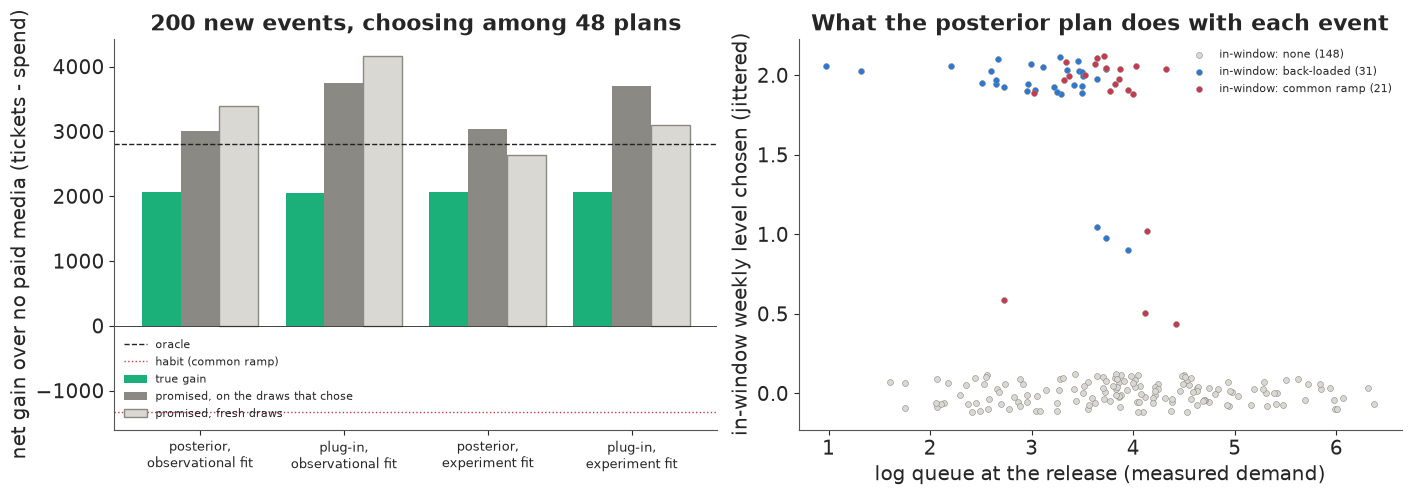

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
ax = axes[0]
labs = [r["policy"] for r in res[2:6]]
x_ = np.arange(len(labs))
ax.bar(x_ - 0.27, [r["true gain"] for r in res[2:6]], width=0.27, color=AQUA, label="true gain")
ax.bar(x_, [r["promised"] for r in res[2:6]], width=0.27, color=MUTED, label="promised, on the draws that chose")
ax.bar(x_ + 0.27, [r["promised, fresh draws"] for r in res[2:6]], width=0.27, color=LIGHT, edgecolor=MUTED,
       label="promised, fresh draws")
ax.axhline(res[1]["true gain"], color=INK, lw=1, ls="--", label="oracle")
ax.axhline(res[0]["true gain"], color=RED, lw=1, ls=":", label="habit (common ramp)")
ax.axhline(0, color=INK, lw=0.6)
ax.set_xticks(x_, [l.replace("over posterior draws", "posterior").replace("plug-in at the posterior mean", "plug-in")
                  .replace(", ", ",\n") for l in labs], fontsize=9)
ax.set(ylabel="net gain over no paid media (tickets - spend)", title=f"{NEV} new events, choosing among {len(CANDS)} plans")
ax.legend(fontsize=8)
ax = axes[1]
ch, ps = CH["over posterior draws, experiment fit"]
cc_ = {"none": LIGHT, "back-loaded": BLUE, "common ramp": RED, "even": PURPLE, "front-loaded": ORANGE, "pulsed": AQUA}
for s, col in cc_.items():
    m_ = np.array([CANDS[c][1] for c in ch]) == s
    if m_.any():
        ax.scatter(q_n[m_], np.array([CANDS[c][2] for c in ch])[m_] + rng.uniform(-0.12, 0.12, m_.sum()), s=18,
                   color=col, edgecolor=MUTED, lw=0.4, label=f"in-window: {s} ({m_.sum()})")
ax.set(xlabel="log queue at the release (measured demand)", ylabel="in-window weekly level chosen (jittered)",
       title="What the posterior plan does with each event")
ax.legend(fontsize=8);

**Hot events** (top third of the queue) get almost no in-window spend, none in 63 of 67 cases:
their pool sells them out (the model puts the chance at 81%), and in-window money can only buy
tickets that someone in the queue would have bought. Their real decisions are a second date, for
which the queue measures the demand left over, or moving the money elsewhere. **Middle events**,
close to capacity, get in-window spend in 23 of 66 cases, and the habit's own shape, the common
ramp, is chosen as often as back-loaded spend (12 against 11). **Slow sellers** get it in 25 of 67,
mostly back-loaded (20). Front-loaded, pulsed and even schedules are never chosen over the
posterior, and the plug-in makes much the same choices. So the habit's shape is not what loses
1,330; its use on every event, hot and nearly full ones included, is. The right panel shows the
chosen in-window level against the release queue: no event above a log queue of about 4.5 gets
any, and where money is spent it is mostly at the top level, 2, the common ramp toward the upper
end of the range (log queue 3-4.4) and back-loaded spend lower down.

### G2 · Re-plan from the pace

A plan made at the announcement can be revised as sales come in. At three checkpoints - after the
second on-sale week, at lead week 8 and at lead week 3 - we reweight each event's posterior draws
by the likelihood of its weekly sales so far (the sell-out week censored), importance sampling
with the event's own data, and choose the rest of its schedule from six options: keep the plan,
stop, even at 0.5 or 1, or back-loaded at 1 or 2. Two variants keep the data useful for next
season's model: **exploration**, a uniformly random option 20% of the time, logged; and a **logged
random factor**, every week of in-window spend multiplied by its own lognormal factor (sd 0.15),
kept through every revision, the recorded version of E104's pacing noise and its instrument. Two
seasons of 150 new events, with the experiment fit.

In [21]:
OPTS = [("keep", 0.0), ("stop", 0.0), ("even", 0.5), ("even", 1.0), ("back", 1.0), ("back", 2.0)]
EPS, FAC_SD = 0.2, 0.15


def future_shape(fut, kind, lv):
    if kind == "stop":
        return np.zeros(fut.shape)
    r = (np.ones(fut.shape) if kind == "even" else np.exp(-LEADW[None, :] / 8.0) * np.ones(fut.shape)) * fut
    return lv * r / np.maximum(r.sum(1, keepdims=True) / np.maximum(fut.sum(1, keepdims=True), 1), 1e-9)


def loglik(mu_al, D, idx, obs):
    """Per event and draw: NegBin log-likelihood of the weeks seen so far, the sell-out week censored."""
    mu, al = mu_al
    p = al / (al + mu)
    lp = stats.nbinom.logpmf(D["y"][idx][..., None], al, p)
    ls = stats.nbinom.logsf(D["rem"][idx][..., None] - 1, al, p)
    return np.where((D["cens"][idx] & obs)[..., None], ls, np.where((D["live"][idx] & obs)[..., None], lp, 0.0)).sum(1)


def run_season(seed, policy, post):
    ev = new_season(seed)
    rs = np.random.default_rng(seed + 5)
    idx = np.sort(rs.choice(E, 150, replace=False))
    ch = choose(post, ev, idx, False, seed + 7)["ch"]             # pre-sale at the announcement, in-window at the release
    Sx = np.vstack([sched(ev, idx[i:i + 1], *CANDS[c][1:])[0] for i, c in enumerate(ch)])
    dPv = np.array([CANDS[c][0] for c in ch])
    ev2 = dict(ev, pool=ev["pool"].copy())
    ev2["pool"][idx] = ev["pool0"][idx] * np.exp(GAMMA * (ev["P"][idx] + dPv))
    dr = event_draws(post, ev, idx, np.random.default_rng(seed + 9), dP=dPv, logq=ev["logQ"][idx] + GAMMA * dPv)
    n = ev["n"][idx]
    Sb = Sx.copy()                                                # the schedule as planned, before any factor
    fac = (np.random.default_rng(seed + 15).lognormal(-FAC_SD ** 2 / 2, FAC_SD, Sx.shape)
           if policy == "re-plan, random factor" else np.ones(Sx.shape))   # one logged factor per event-week
    Sx = Sb * fac
    explored = np.zeros((len(idx), 3), bool)                      # logged exploration picks, per checkpoint

    def sim(Sx_):
        Sf = np.zeros((E, W))
        Sf[idx] = Sx_
        return simulate(ev2, dict(S=Sf), seed + 11)

    steps = []
    if policy != "fixed plan":
        for ci, (cp, lc) in enumerate([("after on-sale week 1", n - 3), ("lead week 8", np.full(len(idx), 8)),
                                       ("lead week 3", np.full(len(idx), 3))]):
            lc = np.minimum(lc, n - 3)
            D = sim(Sx)
            obs = LEADW[None, :] > lc[:, None]
            fut = (LEADW[None, :] <= lc[:, None]) & (LEADW[None, :] < n[:, None])
            sold = (D["cens"][idx] & obs).any(1)
            ll = loglik(mu_cells(dr, ev, idx, Sx), D, idx, obs)
            w = np.exp(ll - logsumexp(ll, 1, keepdims=True))      # this event's draws, reweighted by its pace
            rem_cap = ev["cap"][idx] - (D["y"][idx] * obs).sum(1)
            vals = np.zeros((len(idx), len(OPTS)))
            for j, (kind, lv) in enumerate(OPTS):
                Sfut = Sx * fut if kind == "keep" else future_shape(fut, kind, lv) * fac   # as it would be spent
                tk, spd, _ = play(mu_cells(dr, ev, idx, Sx * obs + Sfut), rem_cap, Sfut,
                                  np.random.default_rng(seed + 13), mask=fut)
                vals[:, j] = ((LAM * tk - spd) * w).sum(1)
            pick = vals.argmax(1)
            if policy == "re-plan, explore":                       # a uniformly random option, logged, 20% of the time
                u = rs.random(len(idx)) < EPS
                pick = np.where(u, rs.integers(0, len(OPTS), len(idx)), pick)
                explored[:, ci] = u & ~sold
            v0 = LAM * D["total"][idx] - D["spend"][idx].sum(1)
            pred = 0.0
            for i in np.flatnonzero(~sold):
                kind, lv = OPTS[pick[i]]
                if kind != "keep":
                    Sb[i] = Sb[i] * obs[i] + future_shape(fut[i:i + 1], kind, lv)[0]
                pred += vals[i, pick[i]] - vals[i, 0]
            Sx = Sb * fac                                         # every revised week keeps its own logged factor
            D2 = sim(Sx)
            steps.append(dict(checkpoint=cp, predicted=pred, true=((LAM * D2["total"][idx] - D2["spend"][idx].sum(1))
                                                                   - v0).sum(),
                              changed=int(np.sum((pick != 0) & ~sold)), ess=np.median(1 / (w ** 2).sum(1)),
                              explored=int(explored[:, ci].sum())))
    D = sim(Sx)
    D0 = simulate(ev, dict(S=np.zeros((E, W))), seed + 11)
    gain = (LAM * D["total"][idx] - D["spend"][idx].sum(1) - dPv - LAM * D0["total"][idx]).sum()
    return gain, steps, dict(factor=fac, explored=explored, D=D, ev=ev2, idx=idx)   # the log next season can learn from


t0 = time.time()
rows_s, steps_s = [], []
for s in range(2):
    for pol in ("fixed plan", "re-plan", "re-plan, explore", "re-plan, random factor"):
        g, st_, _ = run_season(3000 + 100 * s, pol, post_x)
        rows_s.append(dict(season=s, policy=pol, gain=g))
        steps_s += [dict(season=s, policy=pol, **d) for d in st_]
Rs = pd.DataFrame(rows_s).pivot(index="season", columns="policy", values="gain")
Rs.loc["mean"] = Rs.mean()
print(f"two seasons of 150 new events, experiment fit; {time.time() - t0:.0f} s")
print(Rs[["fixed plan", "re-plan", "re-plan, explore", "re-plan, random factor"]].round(0).to_string())
print(pd.DataFrame(steps_s).query("policy == 're-plan'").round(0).to_string(index=False))

two seasons of 150 new events, experiment fit; 44 s
policy  fixed plan  re-plan  re-plan, explore  re-plan, random factor
season                                                               
0           1084.0   1298.0             969.0                  1354.0
1           1568.0   1802.0            1099.0                  1804.0
mean        1326.0   1550.0            1034.0                  1579.0
 season  policy           checkpoint  predicted  true  changed  ess  explored
      0 re-plan after on-sale week 1      113.0  42.0       57 95.0         0
      0 re-plan          lead week 8      137.0  33.0       56 61.0         0
      0 re-plan          lead week 3       95.0 139.0       43 48.0         0
      1 re-plan after on-sale week 1       53.0  29.0       46 91.0         0
      1 re-plan          lead week 8       52.0  76.0       42 64.0         0
      1 re-plan          lead week 3      112.0 130.0       45 51.0         0


Re-planning beat the fixed plan in both seasons, by 20% and 15% (1,300 against 1,080, and 1,800
against 1,570). The last checkpoint paid more than predicted in both seasons (139 and 130 against
95 and 112); the first two mostly paid less than predicted (42 against 113 at the first in one
season, 33 against 137 at lead week 8), though once more (76 against 52): the early and middle
weeks say little about the end. The importance weights thin from a median of 91-95 effective
draws of 150 at the first checkpoint to 45-64 later. Uniform exploration cost a
quarter of re-planning's value in one season and two fifths in the other (970 and 1,100), below
the fixed plan in both. The logged random factor sat within 5% of re-planning in both seasons
(1,350 and 1,800). The two seasons differ by more than any policy difference within them (the
fixed plan gained 1,080 in one and 1,570 in the other), so these are rough sizes, not a ranking;
exploration's loss is clear in both. Re-planning is worth having, a small logged factor is cheap,
and randomising the choice itself is expensive. Thompson sampling (Russo et al. 2018), acting on a
single posterior draw, explores only where the posterior is unsure; we would expect its cost to
fall between the two, but have not run it.

### G3 · Pull-forward and the final weeks

E104 showed that daily lift is not incremental sales when ads bring forward buyers who would have
bought later. Does pull-forward flatter early spend in a timing analysis? We make every event a
timing experiment, with no capacity, and let half of all media buyers of the late build ($\phi =
0.5$) be taken from the event's own later sales; we fit the fast pool model with $\beta$ in three
bands of lead weeks, and count the net extra tickets per event, by shape, against the same world
without media.

In [22]:
t0 = time.time()
pf = []
for r in range(2):
    ev, plan = world(1200 + r, exp_share=1.0)                    # every event gets a random shape
    zero = dict(S=np.zeros_like(plan["S"]))
    for phi in (0.0, 0.5):
        D = simulate(ev, plan, 1300 + r, capped=False, stop=False, phi=phi)
        D0 = simulate(ev, zero, 1300 + r, capped=False, stop=False, phi=phi)
        bb = fit_fast(panel(ev, D), beta="bands", censor=False)
        row = dict(world=r, phi=phi, **{f"beta {a}-{b}": bb[i] for i, (a, b) in enumerate(BANDS)})
        for sh in SHAPES[1:]:
            row[f"net extra tickets per event: {sh}"] = (D["total"] - D0["total"])[plan["shape"] == sh].mean()
        pf.append(row)
pf = pd.DataFrame(pf)
bt_band = [np.mean(beta_true(np.arange(a, b + 1))) for a, b in BANDS]
print(f"pull-forward worlds, no capacity, {time.time() - t0:.0f} s; true beta averaged over each band: "
      + ", ".join(f"{v:.3f}" for v in bt_band))
print(pf.groupby("phi").mean().drop(columns="world").round(3).T.to_string())
k_rush = (ev["n"][:, None] - 1 - LEADW[None, :]) < 2
print("share of each shape's spend in on-sale weeks 0-1, where the rush is: " + ", ".join(
    f"{sh} {plan['S'][(plan['shape'] == sh)[:, None] & k_rush].sum() / plan['S'][plan['shape'] == sh].sum():.1%}"
    for sh in SHAPES[1:]))

pull-forward worlds, no capacity, 4 s; true beta averaged over each band: 0.159, 0.072, 0.033
phi                                           0.0     0.5
beta 0-3                                    0.208   0.127
beta 4-11                                   0.066   0.069
beta 12-38                                  0.041   0.045
net extra tickets per event: front-loaded  12.901  11.874
net extra tickets per event: back-loaded   44.169  18.323
net extra tickets per event: pulsed        13.161  10.358
net extra tickets per event: even          11.746   8.415
share of each shape's spend in on-sale weeks 0-1, where the rush is: front-loaded 23.3%, back-loaded 1.3%, pulsed 14.8%, even 8.1%


Start with no pull-forward. The banded fast fit gives 0.21, 0.066 and 0.041 against true band
averages of 0.16, 0.072 and 0.033, a third high in the final weeks and a quarter high beyond
twelve. Budgets and shapes are random here, so this is not confounding: a three-step function
cannot follow $0.03 + 0.17 e^{-l/5}$, and the fast estimator is biased even without tilt or
pacing. So the change, not the level, is what to read.

Pull-forward does not flatter early spend here. With $\phi = 0.5$ the final-weeks band falls from
0.21 to **0.13**, now a fifth below the truth, while the other two barely move (0.066 to 0.069,
0.041 to 0.045). Pulled buyers come out of the last weeks, the busiest of the walk-up, so the
weekly model sees a lower baseline exactly where late spend sits and reads it as a weaker
response. The net value of back-loaded spend falls most, from about 44 extra tickets per event to
18, front-loaded spend least, from 13 to 12. A model of weekly sales absorbs part of pull-forward
into its baseline; the net shows only in event totals under randomised designs, as in E104.

The shapes do not test Mahajan & Muller's curvature argument: pulsed beats even (13 against 12
extra tickets per event) partly because it puts 15% of its spend in on-sale weeks 0-1, where the
rush multiplies media, against 8% for even spend. Testing curvature takes budget variation within
events at matched lead weeks.

### Where this leaves the planner

The answer to when to spend, by event type, is this. Pre-sale money goes in at the announcement,
before anyone knows which events are hot; at the release, hot events get almost no in-window
money, events near capacity get it about a third of the time, as often in the common ramp's
on-sale-and-final-push shape as back-loaded, and slow sellers get it mostly back-loaded. Counting
carryover, money one or two weeks before the event buys the most. That answer rests on three
things. The response by lead time $\beta(l)$ was recovered only by the experiment that randomised
budget as well as timing. The pre-sale effect $\gamma$ is weakly identified, and its point
estimates sit above the truth, so the all-in pre-sale choice may be too generous. And the planner
simulated with no pull-forward: G3 shows that back-loaded spend, the slow sellers' advice, is
exactly what pull-forward cuts most, and that weekly fits cannot see it. The ranking of shapes is
the planted curve's; a platform's own curve could rank them differently. What carries over is the
procedure: randomise timing and budget, fit, choose each part of the plan on what is known when it
is decided, and check the promises.

## H · Films and games

**Films** are E106's subject: when a studio should spend before a release, with the release clock,
screens as a mediator and P&A schedules worked through on real release calendars. **Games** add
one thing this notebook can say. A wishlist is the game's queue, a noisy measurement of the pool
before launch, and it is also a mediator, since pre-launch spend builds it, as E104 noted. Our
queue is both too: in part F it measures the rush level, and that rush level holds the effect of
pre-sale spend $P_e$. Conditioning on the wishlist to judge the trailer budget would remove the
effect being measured; the model has to put the spend upstream of the measurement, as part F's
does. E104's part H covers the other games trap, launch delays that move the t-minus clock under
spend already made.

In [23]:
print(f"total run time {time.time() - T_START:.0f} s")

total run time 320 s


## Summary

- **Lining events up by lead time reads the on-sale rush as media.** The lead-time model gave 0.93
  against a true 0.10 (-2.18 under flat spend), and was right only with equal windows. A
  log-additive on-sale clock was not enough (0.118; 0.07-0.21 under flat spend). The pool model
  recovered 0.09-0.11 in part C, and later only with censoring and fixed effects or Mundlak.
- **Instant sell-outs carry no information about media and little about demand.** Censoring took
  0.41 to 0.108, and dropping the instant sell-outs changed nothing (0.107), with one common effect
  for all events. Their demand came out at a fifth of the truth without an outside signal and at
  0.85 with a queue whose noise is the planted 0.3.
- **Rescue budgets flip E104's random-intercept trap.** Random effects gave 0.033 against 0.107 for
  fixed effects, and Mundlak restored 0.107; pre-sale money given to the big tours made its effect
  look ten times its size. Two simulated worlds per row.
- **Observational timing estimates were biased in a world where slow sellers walk up late and get
  the rescue and pacing money.** With a lead curve per hotel and healthy diagnostics, the
  final-week response came out at 0.31 (0.25-0.38) against 0.20; a timing-only experiment whose
  events held their schedules was still high (0.24), pointing at the budget rule more than pacing.
  A timing-and-budget experiment gave 0.22 (0.17-0.27), covering the truth at every lead week in
  this one world, and recovered the planted pattern that money one or two weeks out buys the most.
- **Every plan over-promised, and pre-sale money had to be chosen blind.** The fitted policies
  gained about 2,050 against an oracle's 2,800 and -1,330 for the habit; peeking at the release
  queue would have added 150. Promises ran 440-2,100 high even on fresh draws, as the late build
  was off and $\gamma$ weakly identified. Hot events got almost no in-window spend (none in 63 of
  67); the shape ranking is the planted curve's.
- **Re-planning gained 15-20% over the fixed plan in two seasons**, less than the season-to-season
  spread; uniform exploration cost a quarter to two fifths, a logged random factor within 5%.
- **Pull-forward hides in the final weeks' baseline.** It took the final-weeks band from 0.21 to
  0.13 (true 0.16) and back-loaded spend's net value from 44 to 18 tickets per event, the very
  spend the plan recommends for slow sellers.

## Try it yourself

1. **Tilt or pacing?** Refit the observational world with the walk-up tilt off, then with
   reactive pacing off, to see which one makes the final-week bias of $\beta(l)$. Then add
   $\tilde q_e \sum_j B_j(l)\, \kappa_j$, centred over lead weeks, to the late build: does the
   bias go away, or only the misfit of the predictive check by thirds of the queue?
2. **Calibrate instead of pooling.** Fit the observational and the timing-and-budget experiment
   events together, first as one pool (does the bias come back?), then with a bias $\delta(l)$ on
   the spline weights that only the observational events carry (E103's idea). How much narrower
   is $\beta(l)$ than with the experiment alone, and with 30, 60 or all 215 experiment events?
3. **Is a logged factor enough to learn from?** `run_season` returns the factors it drew, the
   exploration picks and the season's final weekly data with its events. Run two re-planned
   seasons with the random factor at sd 0.05, 0.15 and 0.3, refit the fast pool model on each
   season's weekly data with the factor as an instrument (E104's moment condition) and without,
   and set the value of next season's better estimate against this season's cost.